# Credit Risk & Loan Default Prediction

**Advanced Apex Project-2 — Final Submission**  
**Name:** Anil Ghatge  
**BITS ID:** 2025EM1200153  
**Selected problem ID:** P1

## Project Objective

This project develops an initial supervised binary-classification workflow for historical LendingClub loans. The prediction target is derived from `loan_status`: `1` represents a resolved Charged Off/Default outcome and `0` represents a resolved Fully Paid outcome. The objective is to compare application-time financial and credit-history information for its usefulness in ranking historical loan outcomes. Since records can have different observation periods, this label is the status in the supplied dataset snapshot, not a default event within a consistent 36- or 60-month horizon.

## Business Goal

The intended use is historical credit-risk analysis: identify patterns associated with repayment outcomes while balancing missed defaults against false alarms. This exploratory project is not an approval policy and does not establish causal effects, regulatory suitability, or performance on current applicants. Those limits are considered when interpreting results and planning further validation.

## Reproducibility and Run Instructions

**Tested environment:** CPython 3.12.15 with the pinned packages in [`requirements.txt`](./requirements.txt). From this notebook's folder, install once into the Python environment selected by VS Code/Jupyter:

```bash
python -m pip install -r requirements.txt
```

The notebook verifies that the active package versions match the pinned manifest and prints the Python/package versions; it does not install or upgrade packages every time it runs. Select that same environment as the notebook kernel, restart the kernel, and use **Run All** from top to bottom. Running later sections alone requires their earlier variables and fitted objects.

**Dataset:** Kaggle dataset `habiburrohman/lendingclub-loan-dataset`, version 1, file `loan_data_2007_2014.csv`. The loader verifies the file's SHA-256 (`43ecf2dcf074c87215078f33019c1282d9edb0d3569ce052d5ad6a597004c545`) before analysis. The dataset is not bundled with this notebook; the first download requires network access and KaggleHub access. Subsequent runs use its local cache when available.

**Evaluation order:** the notebook first creates chronological model-training, validation, and final-test partitions. EDA and baseline/model selection use development data. Section 11 selects candidates with expanding-window folds contained in model-training months, selects its threshold on the separate validation period, then scores the newest test period once. The final-test class share is shown for split integrity only. Do not tune the model or threshold after viewing that final test result; if you do, a new later holdout is needed for an unbiased final estimate.

Validation CSV exports are written to `model_results/` relative to the notebook kernel's current working directory. Run from the assignment folder if you want those files saved alongside this notebook.


In [33]:
import importlib.metadata as package_metadata
import sys

expected_versions = {
    'ipykernel': '7.4.0',
    'kagglehub': '1.0.3',
    'matplotlib': '3.11.2',
    'numpy': '2.5.5',
    'pandas': '3.1.1',
    'scikit-learn': '1.9.1',
    'seaborn': '0.13.2',
}
missing_distributions = []
version_mismatches = []
for distribution, expected_version in expected_versions.items():
    try:
        package_version = package_metadata.version(distribution)
    except package_metadata.PackageNotFoundError:
        missing_distributions.append(distribution)
    else:
        print(f'{distribution}: {package_version}')
        if package_version != expected_version:
            version_mismatches.append(
                f'{distribution}=={package_version} (expected {expected_version})'
            )

if missing_distributions or version_mismatches:
    raise RuntimeError(
        'Notebook environment does not match requirements.txt. '
        f'Missing: {missing_distributions}; mismatched: {version_mismatches}. '
        'Install the pinned environment, then restart the kernel.'
    )

print(f'Python: {sys.version.split()[0]}')


ipykernel: 7.4.0
kagglehub: 1.0.3
matplotlib: 3.11.2
numpy: 2.5.5
pandas: 3.1.1
scikit-learn: 1.9.1
seaborn: 0.13.2
Python: 3.12.15


## 1. Problem Objective and Dataset Overview

The project uses the LendingClub 2007–2014 historical loan dataset, downloaded from Kaggle dataset version 1, whose file checksum is verified in the loader. The loaded snapshot contains 466,285 rows and 75 original columns before target construction; the code prints the exact loaded dimensions and profiles each column.

The outcome comes from `loan_status`. The model retains only resolved outcomes: Fully Paid (including the credit-policy Fully Paid variant) is coded `0`, and Charged Off/Default (including the credit-policy Charged Off variant) is coded `1`. Current, grace-period, late-but-unresolved, and unlisted or missing statuses are excluded rather than incorrectly treating them as completed outcomes.

Candidate inputs are fields intended to be available around application time, including requested loan amount, annual income, debt-to-income ratio, loan term, home ownership, employment length, and credit-history measures. The data also contains underwriting decisions, identifiers, and repayment/servicing information. Those fields are assessed separately and excluded when unavailable at the intended prediction point, non-generalizable, highly sparse, or likely to leak post-origination outcomes.

## 2. Data Loading, Initial Inspection and Data Split

The loader downloads the pinned Kaggle dataset version 1, selects the expected loan-level CSV, and verifies its SHA-256 checksum before reading it. It raises an error rather than silently choosing among multiple unexpected CSV files. It prints the selected path, dataframe dimensions, and a sample of records. Initial inspection reports column types, missing-value counts, key-field profiles, and exact duplicate rows; exact duplicates are removed before the partitions are made if any are found. The current dataset check found no exact duplicate rows.

The target is created only from explicitly resolved `loan_status` categories. Unresolved loans are excluded because their final outcome is not known in this snapshot. The positive class is the less frequent class (about 19% of resolved records overall), so the split must preserve a meaningful default population in each period.

Rather than randomly shuffling loans, the notebook uses `issue_d` and whole calendar months to approximate a forward-looking evaluation and avoid placing loans from the same month on both sides of a split. The newest complete months, May–December 2014, are reserved as the final test period; the earlier data is split again into model-training (through October 2013) and validation (November 2013–April 2014). Each split is checked for both target classes and non-overlapping date ranges. EDA for modelling choices uses the model-training partition; preprocessing is fit on model-training rows or, for Section 11 cross-validation, within each fold training block; validation supports candidate selection, and the final test is held back for later one-time evaluation.

In [34]:
import hashlib
import os
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight

# Download the LendingClub dataset and select its expected loan-level CSV.
dataset_handle = "habiburrohman/lendingclub-loan-dataset/versions/1"
path = kagglehub.dataset_download(dataset_handle)
csv_files = sorted(
    os.path.join(root, file)
    for root, _, files in os.walk(path)
    for file in files
    if file.lower().endswith('.csv')
)

if not csv_files:
    raise FileNotFoundError(f'No CSV files found in downloaded dataset path: {path}')

expected_file = 'loan_data_2007_2014.csv'
matching_files = [file for file in csv_files if os.path.basename(file) == expected_file]
if matching_files:
    file_path = matching_files[0]
elif len(csv_files) == 1:
    file_path = csv_files[0]
else:
    raise ValueError(
        'Multiple CSV files found and the expected loan-level file was not present: '
        + ', '.join(csv_files)
    )

expected_sha256 = '43ecf2dcf074c87215078f33019c1282d9edb0d3569ce052d5ad6a597004c545'
sha256_digest = hashlib.sha256()
with open(file_path, 'rb') as dataset_file:
    for chunk in iter(lambda: dataset_file.read(1024 * 1024), b''):
        sha256_digest.update(chunk)
actual_sha256 = sha256_digest.hexdigest()
if actual_sha256 != expected_sha256:
    raise ValueError(
        'Dataset checksum mismatch for the pinned version 1 file. '
        f'Expected {expected_sha256}, received {actual_sha256}.'
    )

print(f'Dataset source: {dataset_handle}')
print(f'Dataset SHA-256: {actual_sha256}')
df = pd.read_csv(file_path, low_memory=False)
print(f'Successfully loaded: {file_path}')
print(f'DataFrame shape: {df.shape}')
display(df.head())

Dataset source: habiburrohman/lendingclub-loan-dataset/versions/1
Dataset SHA-256: 43ecf2dcf074c87215078f33019c1282d9edb0d3569ce052d5ad6a597004c545
Successfully loaded: /Users/minalghatge/.cache/kagglehub/datasets/habiburrohman/lendingclub-loan-dataset/versions/1/loan_data_2007_2014.csv
DataFrame shape: (466285, 75)


,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,...,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,0,1077501,1296599,5000,5000,4975.0,36 months,10.65,162.87,B,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1077430,1314167,2500,2500,2500.0,60 months,15.27,59.83,C,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,1077175,1313524,2400,2400,2400.0,36 months,15.96,84.33,C,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,1076863,1277178,10000,10000,10000.0,36 months,13.49,339.31,C,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,1075358,1311748,3000,3000,3000.0,60 months,12.69,67.79,B,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
# Let's inspect the target distribution and key properties of the columns we highlighted
import pandas as pd

# 1. Dimensions check
initial_rows = len(df)
duplicate_count = int(df.duplicated().sum())
print(f'Exact duplicate rows found: {duplicate_count:,}')
if duplicate_count:
    df = df.drop_duplicates().copy()
    print(f'Removed {duplicate_count:,} exact duplicate rows before splitting.')
rows, cols = df.shape
print(f"=== LendingClub Dataset Dimensions ===")
print(f"Total Records (Rows): {rows:,}")
print(f"Total Features (Columns): {cols}\n")

print('=== DataFrame Info ===')
df.info()
print(f'\nExact duplicate rows: {df.duplicated().sum():,}')
print('\nTop 20 columns by missing-value count:')
display(df.isna().sum().sort_values(ascending=False).head(20).rename('Missing values').to_frame())

# 2. Inspect Target Variable Distribution
print("=== Target Variable ('loan_status') Distribution ===")
target_counts = df['loan_status'].value_counts(dropna=False)
target_percent = df['loan_status'].value_counts(normalize=True, dropna=False) * 100
target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage (%)': target_percent.round(2)
})
display(target_summary)

# 3. Analyze Key Features
key_features = [
    'loan_amnt', 'term', 'int_rate', 'installment', 'grade',
    'sub_grade', 'emp_length', 'home_ownership', 'annual_inc',
    'verification_status', 'dti', 'addr_state'
]

print("\n=== Integrity Check on Crucial Columns ===")
feature_analysis = []
for col in key_features:
    if col in df.columns:
        missing_count = df[col].isnull().sum()
        missing_pct = (missing_count / rows) * 100
        dtype = str(df[col].dtype)
        num_unique = df[col].nunique()
        feature_analysis.append({
            'Feature': col,
            'Dtype': dtype,
            'Unique Values': num_unique,
            'Missing Count': missing_count,
            'Missing (%)': f"{missing_pct:.3f}%"
        })
    else:
        feature_analysis.append({
            'Feature': col,
            'Dtype': 'NOT FOUND',
            'Unique Values': 0,
            'Missing Count': 0,
            'Missing (%)': '100%'
        })

display(pd.DataFrame(feature_analysis))

Exact duplicate rows found: 0
=== LendingClub Dataset Dimensions ===
Total Records (Rows): 466,285
Total Features (Columns): 75

=== DataFrame Info ===
<class 'pandas.DataFrame'>
RangeIndex: 466285 entries, 0 to 466284
Data columns (total 75 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Unnamed: 0                   466285 non-null  int64  
 1   id                           466285 non-null  int64  
 2   member_id                    466285 non-null  int64  
 3   loan_amnt                    466285 non-null  int64  
 4   funded_amnt                  466285 non-null  int64  
 5   funded_amnt_inv              466285 non-null  float64
 6   term                         466285 non-null  str    
 7   int_rate                     466285 non-null  float64
 8   installment                  466285 non-null  float64
 9   grade                        466285 non-null  str    
 10  sub_grade                    466285

,Missing values
inq_last_12m,466285
total_bal_il,466285
dti_joint,466285
verification_status_joint,466285
annual_inc_joint,466285
open_acc_6m,466285
open_il_6m,466285
open_il_12m,466285
open_il_24m,466285
mths_since_rcnt_il,466285


=== Target Variable ('loan_status') Distribution ===


,Count,Percentage (%)
loan_status,,
Current,224226,48.09
Fully Paid,184739,39.62
Charged Off,42475,9.11
Late (31-120 days),6900,1.48
In Grace Period,3146,0.67
Does not meet the credit policy. Status:Fully Paid,1988,0.43
Late (16-30 days),1218,0.26
Default,832,0.18
Does not meet the credit policy. Status:Charged Off,761,0.16



=== Integrity Check on Crucial Columns ===


,Feature,Dtype,Unique Values,Missing Count,Missing (%)
0,loan_amnt,int64,1352,0,0.000%
1,term,str,2,0,0.000%
2,int_rate,float64,506,0,0.000%
3,installment,float64,55622,0,0.000%
4,grade,str,7,0,0.000%
5,sub_grade,str,35,0,0.000%
6,emp_length,str,11,21008,4.505%
7,home_ownership,str,6,0,0.000%
8,annual_inc,float64,31901,4,0.001%
9,verification_status,str,3,0,0.000%


### Target Definition and Chronological Split

The `loan_status` mapping deliberately distinguishes completed outcomes from loans whose status is not yet resolved. Fully Paid variants are assigned target `0`; Charged Off and Default variants are assigned target `1`. Current, In Grace Period, late-but-unresolved, missing, and unlisted labels are excluded. This avoids labeling a still-active or delinquent loan as a final default or repayment outcome. Because follow-up time varies across this historical snapshot, the target is not a fixed-horizon default label.

For a realistic temporal holdout, issue dates are parsed as month-year values and complete months are kept together. A boundary near an 80/20 row allocation reserves the newest months for the final test; another boundary within the earlier development period creates a later validation interval. The code verifies that both classes occur in all partitions and that the periods do not overlap. The resulting periods are model-training June 2007–October 2013, validation November 2013–April 2014, and final test May–December 2014. Validation may guide model selection; the final-test outcomes must not guide feature engineering, tuning, or threshold selection.

In [36]:
import pandas as pd

# Define the outcome using only resolved loan statuses.
# Positive = charged off/default; negative = fully paid.
default_statuses = [
    'Charged Off',
    'Default',
    'Does not meet the credit policy. Status:Charged Off',
]
fully_paid_statuses = [
    'Fully Paid',
    'Does not meet the credit policy. Status:Fully Paid',
]
resolved_statuses = default_statuses + fully_paid_statuses

print(f'Initial shape: {df.shape}')
filtered_df = df[df['loan_status'].isin(resolved_statuses)].copy()
filtered_df['target'] = filtered_df['loan_status'].isin(default_statuses).astype('int8')

excluded_status_counts = df.loc[~df['loan_status'].isin(resolved_statuses), 'loan_status'].value_counts()
print(f'Resolved-loan shape: {filtered_df.shape}')
print('Target distribution (0 = fully paid, 1 = charged off/default):')
print(filtered_df['target'].value_counts().sort_index())
print((filtered_df['target'].value_counts(normalize=True).sort_index() * 100).round(2))
print('Excluded unresolved statuses:')
print(excluded_status_counts)

Initial shape: (466285, 75)
Resolved-loan shape: (230795, 76)
Target distribution (0 = fully paid, 1 = charged off/default):
target
0    186727
1     44068
Name: count, dtype: int64
target
0    80.91
1    19.09
Name: proportion, dtype: float64
Excluded unresolved statuses:
loan_status
Current               224226
Late (31-120 days)      6900
In Grace Period         3146
Late (16-30 days)       1218
Name: count, dtype: int64


### Chronological Validation Split

The development partition is split once more by complete `issue_d` months. Earlier loans form the model-training set and later loans form the validation set, while the reserved newest months remain the final test set. This ordering is appropriate for loan records because it better resembles applying a model to loans originated after the data used to fit it; random stratification could mix older and newer lending patterns across partitions.

The implementation selects the month boundary nearest an 80/20 row split, then checks that both classes are present and that training, validation, and test date ranges are strictly ordered. The executed split contains 148,179 training rows, 38,673 validation rows, and 43,943 final-test rows. Default shares are approximately 18.08%, 20.91%, and 20.90%, respectively. These differences are reported rather than corrected through resampling because validation and test should retain their observed period-specific class distributions. The final-test share is used only as a split-integrity description; it is not used to fit, tune, or select the model or threshold.

In [37]:
# Split resolved loans chronologically into development (~80%) and final test (~20%) by whole issue months.
issue_dates = pd.to_datetime(filtered_df['issue_d'], format='%b-%y', errors='coerce')
if issue_dates.isna().any():
    raise ValueError('Some issue_d values could not be parsed.')

month_counts = issue_dates.value_counts().sort_index()
if len(month_counts) < 2:
    raise ValueError('At least two issue months are required.')

cumulative_counts = month_counts.cumsum().iloc[:-1]
target_dev_rows = len(filtered_df) * 0.80
test_month_index = int(np.abs(cumulative_counts - target_dev_rows).to_numpy().argmin())
test_start_date = pd.Timestamp(month_counts.index[test_month_index + 1])

dev_mask = issue_dates < test_start_date
development_df = filtered_df.loc[dev_mask].copy()
test_df = filtered_df.loc[~dev_mask].copy()

if development_df['target'].nunique() < 2 or test_df['target'].nunique() < 2:
    raise ValueError('Both classes must be present in development and final test sets.')
if issue_dates.loc[dev_mask].max() >= issue_dates.loc[~dev_mask].min():
    raise AssertionError('Development and final test months overlap.')

print(f'Final test period starts: {test_start_date:%b %Y}')
print(f'Development rows: {len(development_df):,}')
print(f'Final test rows: {len(test_df):,}')


Final test period starts: May 2014
Development rows: 186,852
Final test rows: 43,943


In [38]:
import numpy as np

# Split the stable development period again, preserving whole issue months.
development_dates = pd.to_datetime(development_df['issue_d'], format='%b-%y', errors='coerce')
if development_dates.isna().any():
    raise ValueError('Some development issue_d values could not be parsed.')

development_month_counts = development_dates.value_counts().sort_index()
if len(development_month_counts) < 2:
    raise ValueError('At least two development issue months are required.')

cumulative_development_counts = development_month_counts.cumsum().iloc[:-1]
target_fit_rows = len(development_df) * 0.80
validation_month_index = int(
    np.abs(cumulative_development_counts - target_fit_rows).to_numpy().argmin()
)
validation_start_date = pd.Timestamp(
    development_month_counts.index[validation_month_index + 1]
)
fit_mask = development_dates < validation_start_date

train_df = development_df.loc[fit_mask].copy()
validation_df = development_df.loc[~fit_mask].copy()
fit_dates = development_dates.loc[fit_mask]
validation_dates = development_dates.loc[~fit_mask]
final_test_dates = pd.to_datetime(test_df['issue_d'], format='%b-%y', errors='coerce')

if train_df['target'].nunique() < 2 or validation_df['target'].nunique() < 2:
    raise ValueError('Both classes must be present in model-training and validation sets.')
if fit_dates.max() >= validation_dates.min():
    raise AssertionError('Model-training and validation months overlap.')
if validation_dates.max() >= final_test_dates.min():
    raise AssertionError('Validation period must end before the final test period.')

print(f'Validation period starts: {validation_start_date:%b %Y}')
print(f'Model-training period: {fit_dates.min():%b %Y} to {fit_dates.max():%b %Y}')
print(f'Validation period: {validation_dates.min():%b %Y} to {validation_dates.max():%b %Y}')
print(f'Final test period: {final_test_dates.min():%b %Y} to {final_test_dates.max():%b %Y}')
print(f'Model-training rows: {len(train_df):,}')
print(f'Validation rows: {len(validation_df):,}')
print(f'Final test rows: {len(test_df):,}')

for split_name, split_frame in [
    ('Model train', train_df),
    ('Validation', validation_df),
    ('Final test', test_df),
]:
    print(f'\n{split_name} target distribution (%):')
    print((split_frame['target'].value_counts(normalize=True).sort_index() * 100).round(2))

Validation period starts: Nov 2013
Model-training period: Jun 2007 to Oct 2013
Validation period: Nov 2013 to Apr 2014
Final test period: May 2014 to Dec 2014
Model-training rows: 148,179
Validation rows: 38,673
Final test rows: 43,943

Model train target distribution (%):
target
0    81.92
1    18.08
Name: proportion, dtype: float64

Validation target distribution (%):
target
0    79.09
1    20.91
Name: proportion, dtype: float64

Final test target distribution (%):
target
0    79.1
1    20.9
Name: proportion, dtype: float64


## 3. Exploratory Data Analysis

EDA is conducted after the chronological partitions exist, and analyses that relate predictors to the outcome use `train_df` only. The notebook first inspects training-partition types, missingness, unique identifiers, and fields that are unavailable at application-time or recorded after origination. This supports later decisions to exclude identifiers, columns with more than 80% missingness, underwriting/post-decision fields, and repayment or servicing leakage fields.

The loan-status plot shows the original status distribution in training data before statuses are collapsed into the binary target. Additional summaries report training-only Spearman correlations and default rates across numeric quantiles, plus counts and default rates for selected low-cardinality categories. Distribution plots compare loan amount, annual income, and DTI between the two resolved classes; income is displayed on a `log1p` scale only for readability. Term and home-ownership counts help expose class composition and small groups.

These descriptive analyses inform metric and preprocessing choices but do not prove causation or out-of-sample predictive value. In particular, the validation and final-test outcomes are not used to choose patterns or features during EDA.

=== Model-training partition ===
Rows: 148,179; columns: 76
Example column at position 20 (or last available): 'desc'
Observed value types in example column:
desc
<class 'str'>    80971
Name: count, dtype: int64

Training columns with >80% missing values: 20


,Missing (%)
mths_since_rcnt_il,100.00
total_bal_il,100.00
total_cu_tl,100.00
inq_fi,100.00
all_util,100.00
max_bal_bc,100.00
open_rv_24m,100.00
open_rv_12m,100.00
il_util,100.00
inq_last_12m,100.00


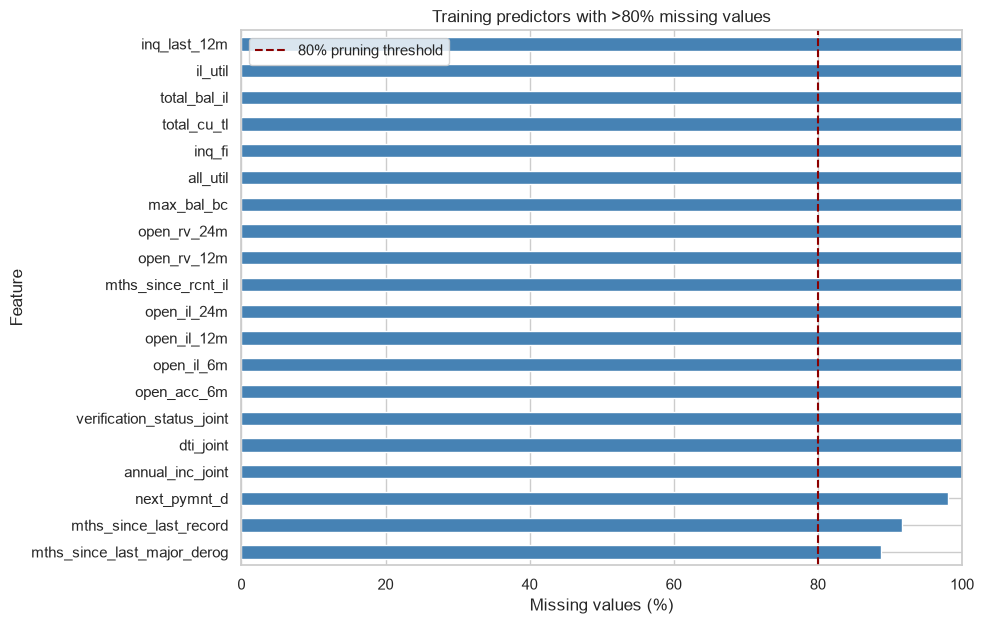


Identifier uniqueness (training partition):
id: 148,179 distinct; unique key=True
member_id: 148,179 distinct; unique key=True
Unnamed: 0: 148,179 distinct; unique key=True

Potential post-decision/post-origination fields excluded from predictor analysis:
['funded_amnt', 'funded_amnt_inv', 'grade', 'sub_grade', 'int_rate', 'installment', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d']


In [39]:
# Profile data quality and scoring-time eligibility on model-training rows only.
if 'train_df' not in globals():
    raise RuntimeError('Create the chronological train/validation/test splits before EDA.')

rows = len(train_df)
warn_col_name = train_df.columns[min(20, len(train_df.columns) - 1)]
print('=== Model-training partition ===')
print(f'Rows: {rows:,}; columns: {train_df.shape[1]:,}')
print(f'Example column at position 20 (or last available): {warn_col_name!r}')
print('Observed value types in example column:')
print(train_df[warn_col_name].dropna().map(type).value_counts())

null_pcts = train_df.isna().mean().mul(100)
high_null_cols = null_pcts[null_pcts > 80].sort_values(ascending=False)
print(f'\nTraining columns with >80% missing values: {len(high_null_cols)}')
display(high_null_cols.round(2).rename('Missing (%)').to_frame())
if not high_null_cols.empty:
    ax = high_null_cols.sort_values().plot(
        kind='barh', figsize=(10, max(4, 0.32 * len(high_null_cols))),
        color='steelblue', title='Training predictors with >80% missing values'
    )
    ax.axvline(80, color='darkred', linestyle='--', label='80% pruning threshold')
    ax.set(xlabel='Missing values (%)', ylabel='Feature', xlim=(0, 100))
    ax.legend(); plt.tight_layout(); plt.show()

identifiers = ['id', 'member_id', 'Unnamed: 0']
print('\nIdentifier uniqueness (training partition):')
for ident in identifiers:
    if ident in train_df.columns:
        print(f'{ident}: {train_df[ident].nunique(dropna=False):,} distinct; '
              f'unique key={train_df[ident].is_unique}')
post_decision = [
    'funded_amnt', 'funded_amnt_inv', 'grade', 'sub_grade', 'int_rate', 'installment',
    'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv',
    'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries',
    'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
    'next_pymnt_d', 'last_credit_pull_d'
]
print('\nPotential post-decision/post-origination fields excluded from predictor analysis:')
print([col for col in post_decision if col in train_df.columns])

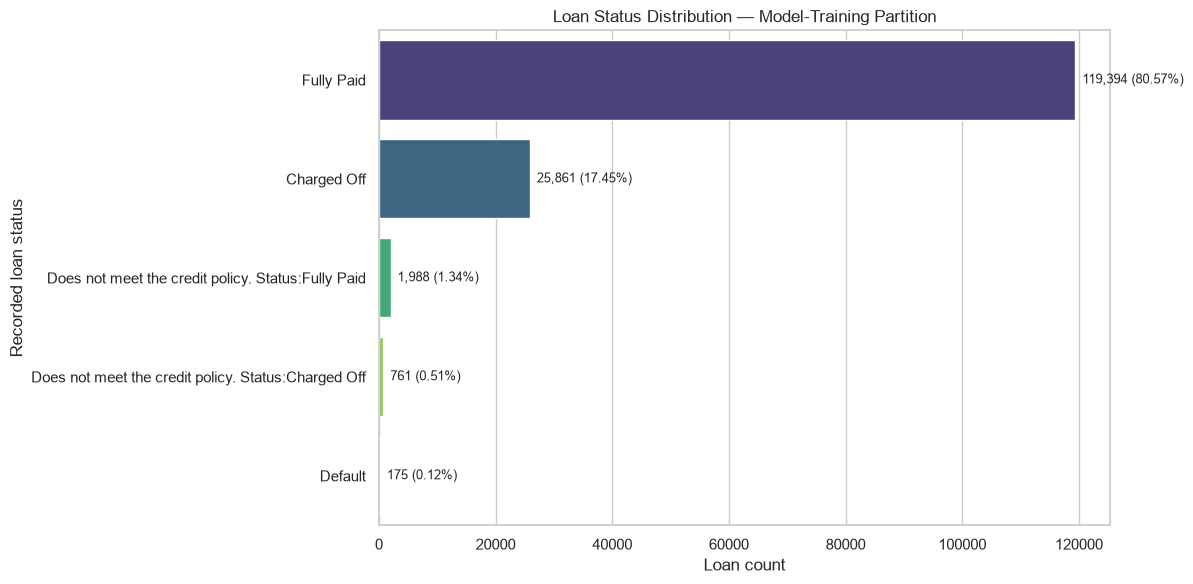

In [40]:
# Plot original outcome statuses in the model-training partition.
if 'train_df' not in globals():
    raise RuntimeError('Create chronological splits before plotting training outcomes.')

sns.set_theme(style='whitegrid')
plt.figure(figsize=(12, 6))
target_order = train_df['loan_status'].value_counts().index
ax = sns.countplot(
    y='loan_status', data=train_df, order=target_order,
    hue='loan_status', palette='viridis', legend=False,
)
total_samples = len(train_df)
for bar in ax.patches:
    percentage = 100 * bar.get_width() / total_samples
    ax.annotate(f'{bar.get_width():,.0f} ({percentage:.2f}%)',
                (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0), textcoords='offset points', va='center', fontsize=9)
ax.set_title('Loan Status Distribution — Model-Training Partition')
ax.set_xlabel('Loan count'); ax.set_ylabel('Recorded loan status')
plt.tight_layout(); plt.show()

### Training-Only Predictor Relationships

For numeric fields such as loan amount, annual income, DTI, open accounts, total accounts, and revolving utilization, the notebook reports missingness and Spearman correlation with the binary target. Spearman correlation is used as a descriptive rank-based measure that does not require a linear relationship. For each numeric field, quantile summaries include the number of loans and observed default rate, helping avoid overinterpreting a rate from a small group.

For selected categorical fields such as term, home ownership, verification status, and purpose, the summaries show group counts and default rates. These analyses run on the model-training partition before imputation and encoding, so the values reflect the raw eligible predictors. They are exploratory descriptions, not a feature-selection rule and not evidence of causal effects.

In [41]:
if 'train_df' not in globals() or 'target' not in train_df.columns:
    raise RuntimeError('Run target construction and chronological splitting first.')

eligible_numeric = [
    col for col in ['loan_amnt', 'annual_inc', 'dti', 'open_acc', 'total_acc', 'revol_util']
    if col in train_df.columns and pd.api.types.is_numeric_dtype(train_df[col])
]
if eligible_numeric:
    numeric_summary = pd.DataFrame({
        'Missing (%)': train_df[eligible_numeric].isna().mean().mul(100).round(2),
        'Spearman correlation with default': train_df[eligible_numeric].corrwith(
            train_df['target'], method='spearman'
        ).round(3),
    }).sort_values('Spearman correlation with default', key=lambda values: values.abs(), ascending=False)
    print('Numeric application-time predictors (training only):')
    display(numeric_summary)
    for col in eligible_numeric:
        bins = pd.qcut(train_df[col], q=10, duplicates='drop')
        grouped = pd.DataFrame({'bin': bins, 'target': train_df['target']}).groupby(
            'bin', observed=True
        )['target'].agg(['count', 'mean'])
        grouped['Default rate (%)'] = grouped.pop('mean').mul(100).round(2)
        print(f'\nDefault rate across {col} quantiles:')
        display(grouped.rename(columns={'count': 'Loan count'}))

eligible_categorical = [
    col for col in ['term', 'home_ownership', 'verification_status', 'purpose']
    if col in train_df.columns and train_df[col].nunique(dropna=False) <= 50
]
for col in eligible_categorical:
    summary = train_df.groupby(col, dropna=False, observed=True)['target'].agg(
        Loans='size', Default_Rate='mean'
    )
    summary['Default_Rate'] = (summary['Default_Rate'] * 100).round(2)
    print(f'\n{col} by resolved outcome (training only):')
    display(summary.sort_values('Default_Rate', ascending=False))
print('EDA uses only model-training rows and application-time candidate fields.')

Numeric application-time predictors (training only):


,Missing (%),Spearman correlation with default
dti,0.00,0.094
revol_util,0.11,0.092
annual_inc,0.00,-0.082
loan_amnt,0.00,0.062
total_acc,0.02,-0.020
open_acc,0.02,0.017



Default rate across loan_amnt quantiles:


,Loan count,Default rate (%)
bin,,
"(499.999, 4000.0]",14913,15.85
"(4000.0, 6000.0]",17541,15.52
"(6000.0, 8000.0]",16456,15.92
"(8000.0, 10000.0]",21105,16.72
"(10000.0, 11100.0]",4282,19.03
"(11100.0, 13200.0]",14748,15.94
"(13200.0, 16000.0]",17697,18.06
"(16000.0, 20000.0]",17291,21.14
"(20000.0, 24250.0]",9464,21.98



Default rate across annual_inc quantiles:


,Loan count,Default rate (%)
bin,,
"(1895.999, 32000.0]",15552,22.25
"(32000.0, 40000.0]",16389,21.84
"(40000.0, 46500.0]",12585,20.62
"(46500.0, 53000.0]",15208,19.79
"(53000.0, 60000.0]",16149,19.48
"(60000.0, 69600.0]",13023,17.70
"(69600.0, 79978.4]",14816,16.82
"(79978.4, 92000.0]",15130,15.47
"(92000.0, 117000.0]",14600,13.47


... (13 outputs left out)

,Loans,Default_Rate
verification_status,,
Verified,59546,21.26
Source Verified,31953,17.91
Not Verified,56680,14.84



purpose by resolved outcome (training only):


,Loans,Default_Rate
purpose,,
small_business,3810,29.06
renewable_energy,197,21.32
other,9566,21.07
educational,422,20.85
medical,1721,19.47
debt_consolidation,82603,19.03
moving,1315,18.56
vacation,968,18.08
house,1151,17.90


EDA uses only model-training rows and application-time candidate fields.


### Selected Feature Distributions by Outcome

The plots compare the training-partition distributions of `loan_amnt`, `annual_inc`, and `dti` for Fully Paid and Charged Off/Default loans. Missing observations are omitted from each plotted distribution, so the separate missingness profile should be consulted when interpreting the shapes. Income is plotted after a display-only `log1p` transformation because its raw scale is strongly right-skewed; the source dataframe is not modified by this visualization.

The term and home-ownership cross-tabs show counts for each outcome class rather than only percentages. Counts provide context for group size and help distinguish common categories from small groups. The purpose of these comparisons is to inform later modeling and data-quality checks, not to infer that a feature causes default.

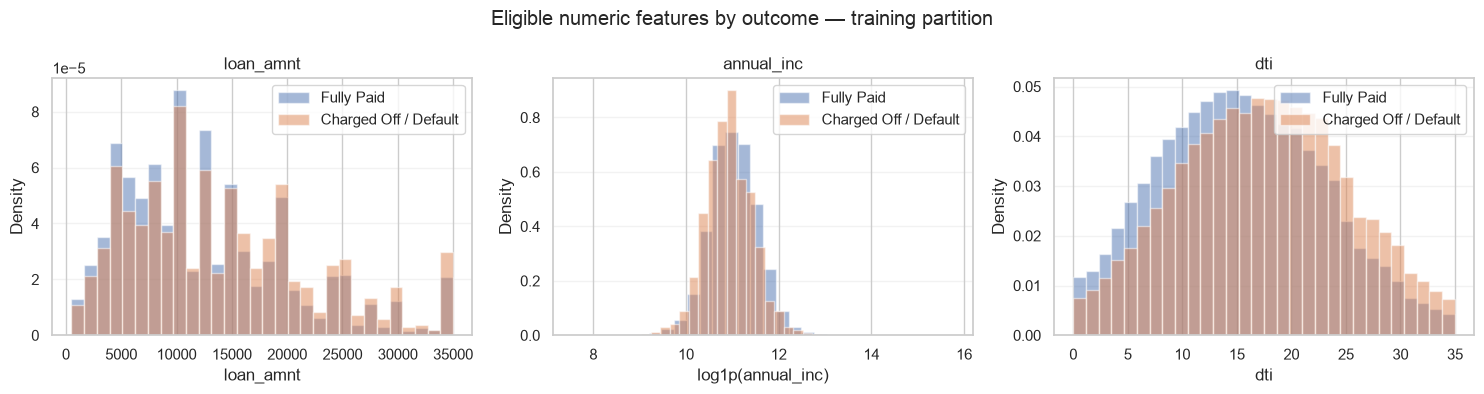


term counts by outcome:


target,Fully Paid,Charged Off / Default
term,,
36 months,102536,17954
60 months,18846,8843


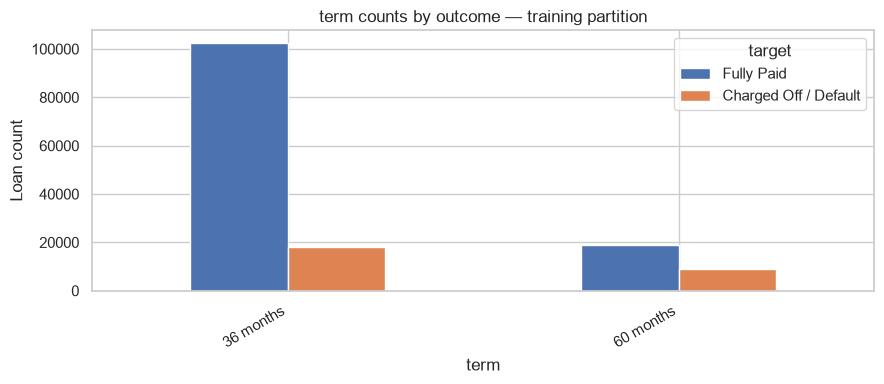


home_ownership counts by outcome:


target,Fully Paid,Charged Off / Default
home_ownership,,
MORTGAGE,59262,11854
NONE,40,8
OTHER,141,38
OWN,9448,2155
RENT,52491,12742


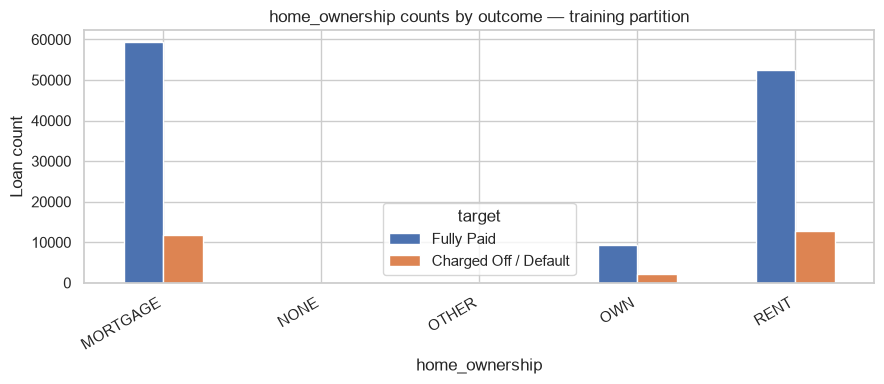

In [42]:
if 'train_df' not in globals() or 'target' not in train_df.columns:
    raise RuntimeError('Run target construction and chronological splitting first.')

labels = {0: 'Fully Paid', 1: 'Charged Off / Default'}
numeric_features = [
    col for col in ['loan_amnt', 'annual_inc', 'dti']
    if col in train_df.columns and pd.api.types.is_numeric_dtype(train_df[col])
]
if numeric_features:
    fig, axes = plt.subplots(1, len(numeric_features), figsize=(5 * len(numeric_features), 4))
    if len(numeric_features) == 1:
        axes = [axes]
    for ax, feature in zip(axes, numeric_features):
        for target_value, label in labels.items():
            values = train_df.loc[train_df['target'] == target_value, feature].dropna()
            if feature == 'annual_inc': values = np.log1p(values.clip(lower=0))
            if not values.empty: ax.hist(values, bins=30, density=True, alpha=0.5, label=label)
        ax.set(title=feature, xlabel='log1p(annual_inc)' if feature == 'annual_inc' else feature,
               ylabel='Density')
        ax.legend(); ax.grid(axis='y', alpha=0.25)
    fig.suptitle('Eligible numeric features by outcome — training partition')
    fig.tight_layout(); plt.show()

for feature in ['term', 'home_ownership']:
    if feature in train_df.columns:
        counts = pd.crosstab(train_df[feature].fillna('(Missing)'), train_df['target'])
        counts = counts.rename(columns={0: 'Fully Paid', 1: 'Charged Off / Default'})
        print(f'\n{feature} counts by outcome:'); display(counts)
        counts.plot(kind='bar', figsize=(9, 4), ylabel='Loan count',
                    title=f'{feature} counts by outcome — training partition')
        plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

### EDA Observations to Record

The executed profile shows substantial sparsity in the model-training partition: 20 columns exceed the 80% missing threshold, including 17 completely empty fields. The identifier check finds `id`, `member_id`, and `Unnamed: 0` unique for every model-training row, supporting their treatment as metadata rather than generalizable predictors. The resolved training population is imbalanced, with an 18.08% default class share; this motivates reporting PR-AUC, recall, precision, and F1 rather than relying on accuracy alone.

Use the tables and plots above to discuss numeric skew and group-level differences, while noting sample counts and missingness. The plots are descriptive: they are not estimates of model performance, do not use the held-out partitions, and do not establish causality. These observations motivate training-only imputation and a deliberate leakage review in the next sections.

## 4. Data Preparation

Data preparation converts the raw partitions into consistent predictor tables without learning from held-out outcomes. First, exact duplicate rows are counted during inspection and removed before the chronological split if present. Then the code drops row identifiers, columns selected by the training-only >80% missingness rule, fields unavailable at the intended application-time scoring point, and post-origination payment or recovery fields that could leak the outcome.

Structured text fields are parsed consistently across all partitions: loan term is converted from strings such as `36 months` to a number, and employment length is converted to a numeric representation. Missing numeric values are imputed with medians and categorical values with modes computed on training data only; the learned values are reused unchanged for validation and test. Numeric outlier caps are likewise learned from the training partition and applied unchanged to the other periods. Categorical encoding is fit conceptually from the training feature set, and validation/test columns are aligned to it. This workflow reduces leakage and ensures comparable model inputs.

In [43]:
# 1. Define columns unavailable at application-time scoring or otherwise unsuitable.
metadata_identifiers = ['id', 'member_id', 'Unnamed: 0']

# These are assigned or finalized during/after underwriting, not at initial application.
post_decision_cols = [
    'funded_amnt', 'funded_amnt_inv', 'grade', 'sub_grade', 'int_rate', 'installment'
]

# These describe loan performance after origination and would leak the outcome.
leakage_cols = [
    'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv',
    'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries',
    'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
    'next_pymnt_d', 'last_credit_pull_d'
]

# Fit the sparsity rule on model-training rows only.
null_percentages = train_df.isnull().mean() * 100
high_sparsity_cols = null_percentages[null_percentages > 80.0].index.tolist()
cols_to_drop = list(dict.fromkeys(
    metadata_identifiers + post_decision_cols + leakage_cols + high_sparsity_cols
))
print(f"Dropping {len(cols_to_drop)} columns due to timing, leakage, metadata, or sparsity.")

train_clean = train_df.drop(columns=cols_to_drop, errors='ignore').copy()
validation_clean = validation_df.drop(columns=cols_to_drop, errors='ignore').copy()
test_clean = test_df.drop(columns=cols_to_drop, errors='ignore').copy()

print(f"Model-training shape after dropping: {train_clean.shape}")
print(f"Validation shape after dropping: {validation_clean.shape}")
print(f"Final-test shape after dropping: {test_clean.shape}")

Dropping 41 columns due to timing, leakage, metadata, or sparsity.
Model-training shape after dropping: (148179, 35)
Validation shape after dropping: (38673, 35)
Final-test shape after dropping: (43943, 35)


In [44]:
# Parse structured text features consistently across all partitions.
def parse_text_features(df_to_clean):
    df_cleaned = df_to_clean.copy()

    if 'term' in df_cleaned.columns:
        term_values = df_cleaned['term'].astype('string').str.replace(' months', '').str.strip()
        df_cleaned['term'] = pd.to_numeric(term_values, errors='coerce')

    if 'emp_length' in df_cleaned.columns:
        emp_length = df_cleaned['emp_length'].astype('string')
        emp_length = emp_length.str.replace(' years', '').str.replace(' year', '')
        emp_length = emp_length.str.replace('+', '', regex=False).str.replace('< 1', '0', regex=False)
        df_cleaned['emp_length'] = pd.to_numeric(emp_length.str.strip(), errors='coerce')

    return df_cleaned

train_clean = parse_text_features(train_clean)
validation_clean = parse_text_features(validation_clean)
test_clean = parse_text_features(test_clean)

print("Parsed 'term' and 'emp_length' in model-training, validation, and final-test data.")
print(train_clean[['term', 'emp_length']].describe())

Parsed 'term' and 'emp_length' in model-training, validation, and final-test data.
            term  emp_length
count   148179.0    143077.0
mean   40.484684     5.63542
std     9.355245    3.586505
min         36.0         0.0
25%         36.0         2.0
50%         36.0         5.0
75%         36.0        10.0
max         60.0        10.0


## 5. Feature Engineering and Selection

After removing ineligible columns and parsing text fields, the notebook creates a small set of deterministic features from application-time sources: loan amount divided by annual income, recent inquiries per open account, a 60-month-term flag, and flags for any prior delinquencies or public records. These transformations are intended to express loan burden and credit-history indicators in a form that is easy to interpret. Ratio values remain missing when a denominator is absent or non-positive; the training-only imputer handles these values later. The same definitions are applied to training, validation, and final test without using target values or partition-level statistics.

Feature exclusions are based on intended scoring time, leakage risk, identifier status, and training-set sparsity—not correlations with the target. The initial encoded feature set includes categoricals with no more than 15 observed training levels; higher-cardinality categoricals are excluded to limit one-hot expansion, with alternative encodings left for future experiments. Continuous predictors are retained rather than binned because binning can discard ordering and within-bin information; quantiles are used only to visualize EDA trends. These are baseline decisions and should be revisited using validation data, not final-test results.

In [45]:
required_feature_sources = [
    'loan_amnt', 'annual_inc', 'inq_last_6mths', 'open_acc', 'term',
    'delinq_2yrs', 'pub_rec'
]
for frame_name, frame in [
    ('train_clean', train_clean),
    ('validation_clean', validation_clean),
    ('test_clean', test_clean),
]:
    missing_sources = [col for col in required_feature_sources if col not in frame.columns]
    if missing_sources:
        raise KeyError(f'{frame_name} is missing feature-engineering inputs: {missing_sources}')

def add_application_features(frame):
    engineered = frame.copy()
    annual_inc = pd.to_numeric(engineered['annual_inc'], errors='coerce')
    open_acc = pd.to_numeric(engineered['open_acc'], errors='coerce')
    inquiries = pd.to_numeric(engineered['inq_last_6mths'], errors='coerce')

    engineered['loan_to_income_ratio'] = pd.to_numeric(
        engineered['loan_amnt'], errors='coerce'
    ).div(annual_inc.where(annual_inc > 0))
    engineered['inquiries_per_open_account'] = inquiries.div(open_acc.where(open_acc > 0))

    term = pd.to_numeric(engineered['term'], errors='coerce')
    engineered['term_60_months'] = term.eq(60).where(term.notna()).astype('float64')

    delinquency = pd.to_numeric(engineered['delinq_2yrs'], errors='coerce')
    engineered['has_prior_delinquency'] = delinquency.gt(0).where(
        delinquency.notna()
    ).astype('float64')

    public_records = pd.to_numeric(engineered['pub_rec'], errors='coerce')
    engineered['has_public_record'] = public_records.gt(0).where(
        public_records.notna()
    ).astype('float64')
    return engineered

train_clean = add_application_features(train_clean)
validation_clean = add_application_features(validation_clean)
test_clean = add_application_features(test_clean)

engineered_feature_names = [
    'loan_to_income_ratio', 'inquiries_per_open_account', 'term_60_months',
    'has_prior_delinquency', 'has_public_record'
]
print('Added application-time features to all three partitions:')
display(train_clean[engineered_feature_names].describe().T.round(3))
print('Missing engineered values are preserved for training-fitted imputation; zero/negative denominators are not divided.')

Added application-time features to all three partitions:


,count,mean,std,min,25%,50%,75%,max
loan_to_income_ratio,148175.0,0.206,0.112,0.001,0.119,0.191,0.280,1.338
inquiries_per_open_account,148148.0,0.103,0.179,0.000,0.000,0.056,0.143,15.500
term_60_months,148179.0,0.187,0.390,0.000,0.000,0.000,0.000,1.000
has_prior_delinquency,148150.0,0.136,0.343,0.000,0.000,0.000,0.000,1.000
has_public_record,148150.0,0.074,0.262,0.000,0.000,0.000,0.000,1.000


Missing engineered values are preserved for training-fitted imputation; zero/negative denominators are not divided.


### Training-Fitted Imputation

Imputation occurs after feature engineering so both original missing predictor values and undefined ratios receive consistent treatment. Numeric medians and categorical modes are calculated from model-training rows only. The exact training-derived values are then applied to model-training, validation, and final-test partitions; validation/test statistics are never used to fill their own missing values. This choice is simple and robust for a baseline, especially for skewed numeric features, while preserving all loans. The cell checks the remaining missing-value totals in all three partitions and plots before/after missingness for the most incomplete retained training predictors.

#### Missing-Value Strategy

Columns with more than 80% missingness in model-training rows are removed before imputation because such sparse fields may be unreliable and can increase feature complexity. The threshold is calculated on training data only and applied unchanged to the other partitions. For retained numeric fields, the median is used because it is less affected than the mean by skew and extreme values. For retained categorical fields, the most frequent training category provides a simple baseline fill while keeping values in the original category vocabulary.

The implementation stores training-derived fill values and applies them to each partition. It reports missing counts afterward and compares training missingness before and after imputation for the 15 most incomplete retained predictors. Imputation does not mean that missingness itself is uninformative; missing-indicator features may be considered in later experiments.

Numerical columns imputed: 24
Categorical columns imputed: 14
Model-training missing values: 0
Validation missing values: 0
Final-test missing values: 0


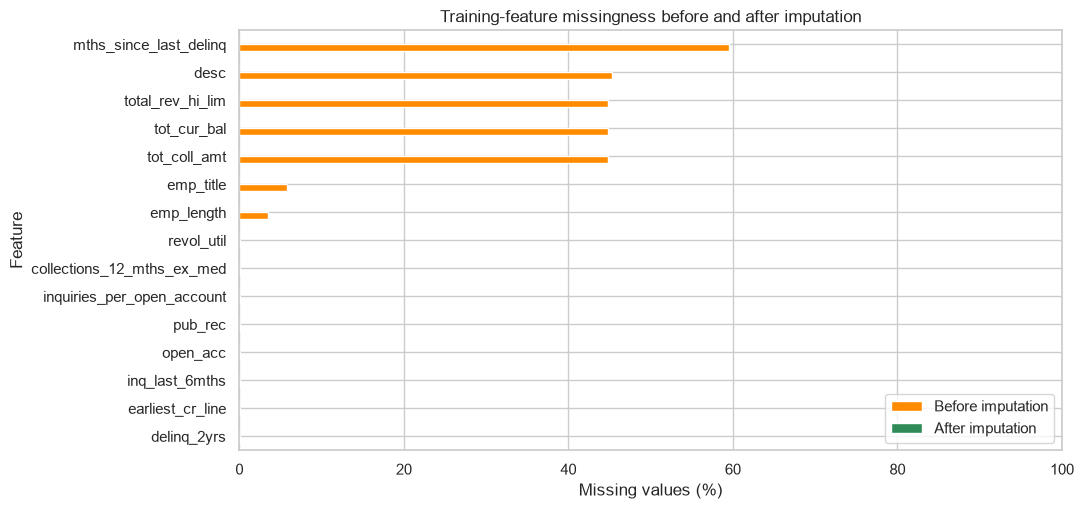

In [46]:
# Identify columns and fit imputation values using model-training data only.
num_cols = train_clean.select_dtypes(include='number').columns.drop('target', errors='ignore').tolist()
cat_cols = [
    col for col in train_clean.columns
    if col != 'loan_status'
    and (
        pd.api.types.is_object_dtype(train_clean[col])
        or pd.api.types.is_string_dtype(train_clean[col])
        or isinstance(train_clean[col].dtype, pd.CategoricalDtype)
    )
]

numeric_fill_values = train_clean[num_cols].median()
categorical_fill_values = {}
for col in cat_cols:
    mode_values = train_clean[col].mode()
    if not mode_values.empty:
        categorical_fill_values[col] = mode_values.iloc[0]

missing_columns = train_clean.drop(columns=['target', 'loan_status'], errors='ignore').columns
missing_before = train_clean[missing_columns].isna().mean().mul(100)

# Apply training-derived imputation values to every partition.
for frame in (train_clean, validation_clean, test_clean):
    for col, fill_value in numeric_fill_values.items():
        frame[col] = frame[col].fillna(fill_value)
    for col, fill_value in categorical_fill_values.items():
        frame[col] = frame[col].fillna(fill_value)

print(f"Numerical columns imputed: {len(numeric_fill_values)}")
print(f"Categorical columns imputed: {len(categorical_fill_values)}")
print(f"Model-training missing values: {train_clean.isnull().sum().sum()}")
print(f"Validation missing values: {validation_clean.isnull().sum().sum()}")
print(f"Final-test missing values: {test_clean.isnull().sum().sum()}")

missing_after = train_clean[missing_columns].isna().mean().mul(100)
missing_comparison = pd.DataFrame({
    'Before imputation': missing_before,
    'After imputation': missing_after,
})
top_missing = missing_before[missing_before > 0].nlargest(15).sort_values().index
if len(top_missing):
    ax = missing_comparison.loc[top_missing].plot(
        kind='barh', figsize=(11, max(4, 0.35 * len(top_missing))),
        color=['darkorange', 'seagreen'], title='Training-feature missingness before and after imputation'
    )
    ax.set(xlabel='Missing values (%)', ylabel='Feature', xlim=(0, 100))
    ax.legend(loc='lower right')
    plt.tight_layout()
    plt.show()
else:
    print('No missing predictor values were present in the model-training partition before imputation.')

### Training-Fitted Outlier Handling

After imputation, the notebook identifies numeric predictors with more than two distinct values and excludes the target and binary indicators. For each eligible predictor, it computes the 1st and 99th percentiles on model-training rows only. Values below or above those bounds are clipped rather than deleting loan records, preserving the chronological partitions and sample sizes. The same bounds are applied to validation and final-test data so their distributions do not influence the fitted preprocessing.

The summary reports the learned bounds and the number of values clipped in each partition. Selected histograms compare training distributions before and after capping. Percentile capping is a conservative baseline against extreme values; it should be checked for business plausibility and is not a claim that every capped observation is erroneous.

Numeric predictors checked and capped: 17
Rows retained in all partitions; only predictor values beyond training percentile caps were clipped.


,Feature,1st percentile cap,99th percentile cap,Model train values capped,Validation values capped,Final test values capped
15,loan_to_income_ratio,0.025311,0.48497,2964,293,542
13,tot_cur_bal,4763.340000,542129.20000,2964,1456,1804
3,dti,0.900000,33.08000,2943,649,1699
10,revol_util,0.100000,97.50000,2927,498,807
14,total_rev_hi_lim,4200.000000,102800.00000,2913,1665,2218
2,annual_inc,17000.000000,230000.00000,2878,586,753
11,total_acc,5.000000,57.00000,2561,734,982
7,open_acc,3.000000,24.00000,2242,854,1171
6,mths_since_last_delinq,2.000000,79.00000,2191,443,567
12,tot_coll_amt,0.000000,733.22000,1482,1496,2105


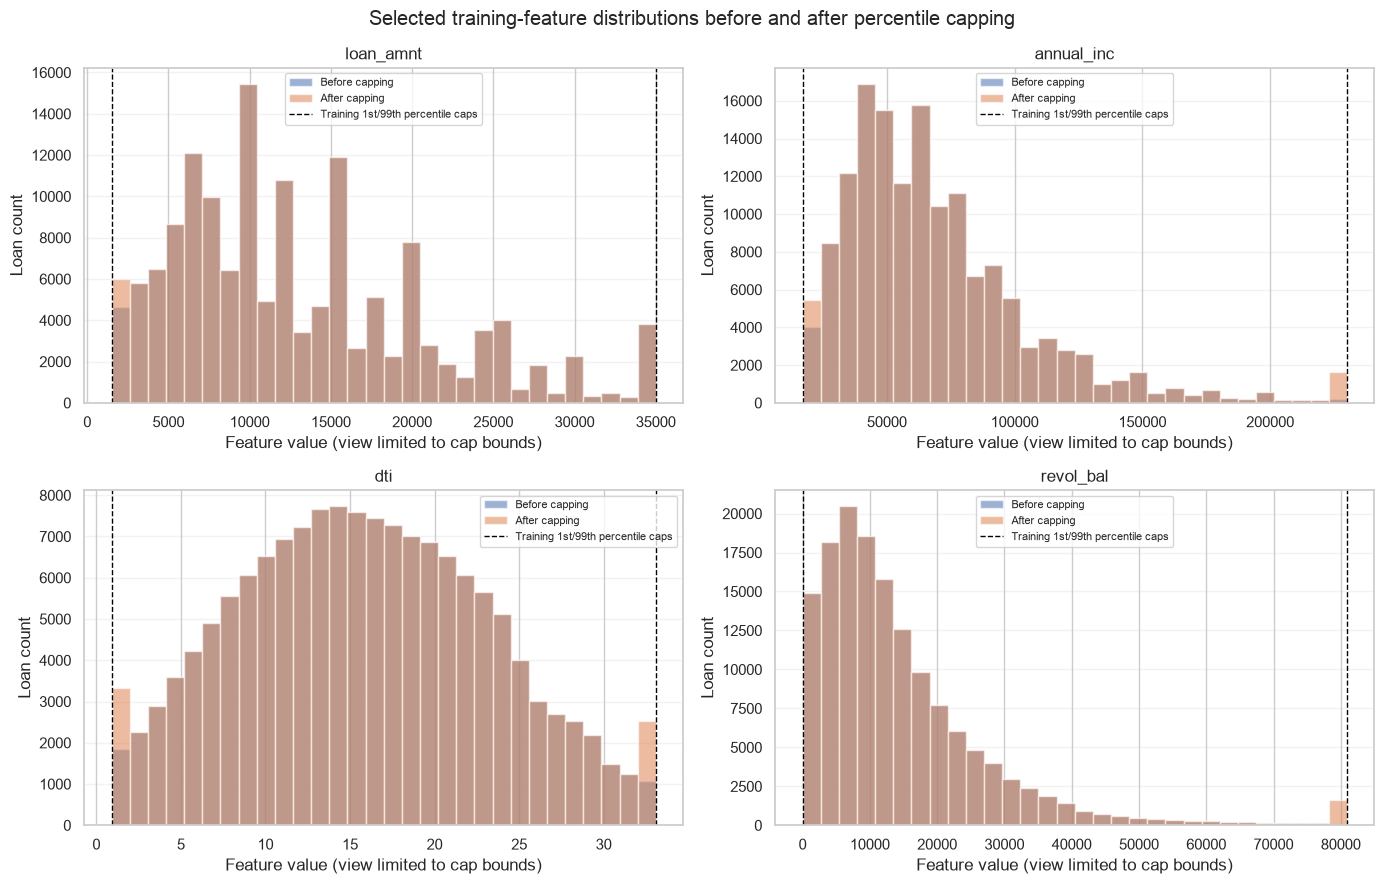

Before-cap histogram bins show only values within the cap bounds; out-of-bound counts appear in the summary table.


In [47]:
# Learn percentile caps from model-training predictors only; leave the target untouched.
numeric_predictors = [
    col for col in train_clean.select_dtypes(include='number').columns
    if col != 'target' and train_clean[col].nunique(dropna=True) > 2
]
import matplotlib.pyplot as plt
preferred_outlier_plot_features = ['loan_amnt', 'annual_inc', 'dti', 'revol_bal', 'tot_cur_bal']
outlier_plot_cols = [col for col in preferred_outlier_plot_features if col in numeric_predictors][:4]
outlier_values_before = {col: train_clean[col].copy() for col in outlier_plot_cols}
outlier_bounds = {}
outlier_records = []

for col in numeric_predictors:
    lower_cap = train_clean[col].quantile(0.01)
    upper_cap = train_clean[col].quantile(0.99)
    if pd.isna(lower_cap) or pd.isna(upper_cap) or lower_cap >= upper_cap:
        continue

    outlier_bounds[col] = (lower_cap, upper_cap)
    record = {
        'Feature': col,
        '1st percentile cap': lower_cap,
        '99th percentile cap': upper_cap,
    }

    for split_name, frame in [
        ('Model train', train_clean),
        ('Validation', validation_clean),
        ('Final test', test_clean),
    ]:
        outside_caps = (frame[col] < lower_cap) | (frame[col] > upper_cap)
        record[f'{split_name} values capped'] = int(outside_caps.sum())
        frame[col] = frame[col].clip(lower=lower_cap, upper=upper_cap)

    outlier_records.append(record)

outlier_summary = pd.DataFrame(outlier_records)
print(f'Numeric predictors checked and capped: {len(outlier_bounds)}')
print('Rows retained in all partitions; only predictor values beyond training percentile caps were clipped.')
display(outlier_summary.sort_values('Model train values capped', ascending=False))

plotted_outlier_cols = [col for col in outlier_plot_cols if col in outlier_bounds]
if plotted_outlier_cols:
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for ax, col in zip(axes.flat, plotted_outlier_cols):
        lower_cap, upper_cap = outlier_bounds[col]
        bins = np.linspace(lower_cap, upper_cap, 31)
        ax.hist(outlier_values_before[col], bins=bins, alpha=0.55, label='Before capping')
        ax.hist(train_clean[col], bins=bins, alpha=0.55, label='After capping')
        ax.axvline(lower_cap, color='black', linestyle='--', linewidth=1)
        ax.axvline(upper_cap, color='black', linestyle='--', linewidth=1,
                   label='Training 1st/99th percentile caps')
        ax.set(title=col, xlabel='Feature value (view limited to cap bounds)', ylabel='Loan count')
        ax.legend(fontsize=8)
        ax.grid(axis='y', alpha=0.25)
    for ax in axes.flat[len(plotted_outlier_cols):]:
        ax.set_visible(False)
    fig.suptitle('Selected training-feature distributions before and after percentile capping')
    fig.tight_layout()
    plt.show()
    print('Before-cap histogram bins show only values within the cap bounds; out-of-bound counts appear in the summary table.')
else:
    print('No selected numeric features had valid percentile bounds to plot.')

### Encoding and Feature-Set Alignment

Categorical predictors with at most 15 distinct training values are one-hot encoded, retaining category indicators. Higher-cardinality columns are excluded in this baseline to keep the expanded feature matrix manageable; this is a computational and simplicity choice, not proof that the fields are uninformative. The encoding is based on the training category set. Validation and final-test matrices are reindexed to the training columns, so an unseen later category does not add a new model feature and missing training categories are represented by zero indicators.

The target and original `loan_status` source field are kept out of the predictor matrices. The code verifies that train, validation, and test feature columns match, that the target is not in the predictors, and that feature/target row counts agree. In later work, higher-cardinality encoding alternatives can be evaluated using training/validation only.

In [48]:
# Keep labels separate from model inputs and bound one-hot feature expansion.
categorical_features = cat_cols
cardinality = train_clean[categorical_features].nunique()
low_card_cat_cols = [col for col in categorical_features if cardinality[col] <= 15]
high_card_cat_cols = [col for col in categorical_features if col not in low_card_cat_cols]

y_train = train_clean['target'].astype('int8').copy()
y_validation = validation_clean['target'].astype('int8').copy()
y_test = test_clean['target'].astype('int8').copy()

print(f"Encoding {len(low_card_cat_cols)} low-cardinality categorical features.")
print(f"Excluding {len(high_card_cat_cols)} high-cardinality features.")

def prepare_model_features(frame):
    return frame.drop(columns=['target', 'loan_status', *high_card_cat_cols], errors='ignore')

train_features = prepare_model_features(train_clean)
validation_features = prepare_model_features(validation_clean)
test_features = prepare_model_features(test_clean)

# Retain every training category so unseen later categories map to all-zero indicators.
train_encoded = pd.get_dummies(
    train_features,
    columns=low_card_cat_cols,
    drop_first=False,
    dtype='int8'
)
validation_encoded = pd.get_dummies(
    validation_features,
    columns=low_card_cat_cols,
    drop_first=False,
    dtype='int8'
).reindex(columns=train_encoded.columns, fill_value=0)
test_encoded = pd.get_dummies(
    test_features,
    columns=low_card_cat_cols,
    drop_first=False,
    dtype='int8'
).reindex(columns=train_encoded.columns, fill_value=0)

print(f"Encoded model-training feature shape: {train_encoded.shape}")
print(f"Encoded validation feature shape: {validation_encoded.shape}")
print(f"Encoded final-test feature shape: {test_encoded.shape}")
assert list(train_encoded.columns) == list(validation_encoded.columns) == list(test_encoded.columns)
assert 'target' not in train_encoded.columns
assert len(train_encoded) == len(y_train)
assert len(validation_encoded) == len(y_validation)
assert len(test_encoded) == len(y_test)

Encoding 6 low-cardinality categorical features.
Excluding 8 high-cardinality features.
Encoded model-training feature shape: (148179, 51)
Encoded validation feature shape: (38673, 51)
Encoded final-test feature shape: (43943, 51)


### Feature-Selection Audit

The audit lists columns removed by the established exclusion rules, their non-null completeness in the model-training partition, and numeric correlations with the target for selected post-decision and leakage fields. The purpose is transparency: some removed fields can look highly predictive precisely because they contain information generated after underwriting or after repayment behavior has begun. Such apparent predictive power does not make a field valid for the intended application-time model.

Correlations are descriptive and are not used as a feature-selection algorithm. Arbitrary category codes, identifiers, and empty/high-sparsity fields are not assigned artificial numeric correlations. The following note distinguishes unavailable post-decision fields from genuine post-origination leakage.

In [49]:
import pandas as pd

if 'train_df' not in locals() or 'cols_to_drop' not in locals():
    raise RuntimeError('Run the target, time-split, and feature-pruning cells first.')

# Audit the columns selected from the established training partition.
audit_cols = [col for col in cols_to_drop if col in train_df.columns]
null_pct = train_df[audit_cols].isna().mean() * 100
completeness_pct = 100 - null_pct

# Avoid assigning arbitrary numeric codes to categorical values for correlation.
numeric_audit_cols = [
    col for col in audit_cols
    if (col in leakage_cols or col in post_decision_cols)
    and pd.api.types.is_numeric_dtype(train_df[col])
]
correlations = train_df[numeric_audit_cols].corrwith(train_df['target'])
column_types = pd.Series(
    [
        'Post-decision' if col in post_decision_cols else
        'Leakage' if col in leakage_cols else
        'Metadata' if col in metadata_identifiers else
        'High Sparsity'
        for col in audit_cols
    ],
    index=audit_cols,
)

audit_summary = pd.DataFrame({
    'Column Type': column_types,
    'Completeness % (Non-Null)': completeness_pct.round(2),
    'Correlation with Target': correlations.round(4),
}).sort_values(by='Correlation with Target', key=lambda values: values.abs(), ascending=False)

print('=== Dropped Columns Audit Summary (Training Partition) ===')
display(audit_summary)

=== Dropped Columns Audit Summary (Training Partition) ===


,Column Type,Completeness % (Non-Null),Correlation with Target
recoveries,Leakage,100.00,0.4585
total_rec_prncp,Leakage,100.00,-0.4141
last_pymnt_amnt,Leakage,100.00,-0.3183
total_pymnt,Leakage,100.00,-0.2980
total_pymnt_inv,Leakage,100.00,-0.2944
collection_recovery_fee,Leakage,100.00,0.2634
int_rate,Post-decision,100.00,0.2344
total_rec_late_fee,Leakage,100.00,0.1433
funded_amnt,Post-decision,100.00,0.0656
funded_amnt_inv,Post-decision,100.00,0.0596


#### Why Excluded Fields Are Not Predictors

`funded_amnt`, `grade`, `sub_grade`, `int_rate`, and `installment` are assigned or finalized during underwriting/funding and are outside this project’s stated pre-approval scoring point. Payment totals, outstanding principal, recoveries, collection fees, and payment dates are generated after origination and can directly reveal repayment progress or the outcome. IDs such as `id` and `member_id` identify records rather than reusable borrower attributes. The model therefore excludes these features even if some show strong historical association with the target. If the scoring point changes, eligibility should be revisited explicitly, while post-origination outcome information must remain excluded.

## 6. Baseline Model and Initial Results

Logistic Regression is used as an interpretable, computationally efficient baseline for binary classification. The model is trained on the earlier model-training period and evaluated on the later chronological validation period; it does not create a new random split or use the final-test set. Continuous numeric predictors are standardized inside the model pipeline, while binary and one-hot columns pass through unchanged. `class_weight='balanced'` gives greater influence to the minority default class during fitting without altering validation/test class distributions.

The initial decision threshold is 0.5, and the code reports accuracy, precision, recall, F1, ROC-AUC, PR-AUC (average precision), and a labeled confusion matrix. PR-AUC and recall are particularly relevant because defaults are less common and missed defaults matter; precision/F1 expose the trade-off in false alarms. The executed validation baseline achieved PR-AUC 0.3463, ROC-AUC 0.6747, accuracy 0.6211, precision 0.3068, recall 0.6445, and F1 0.4157 at threshold 0.5. These are preliminary validation metrics, not final-test estimates.

In [50]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

required_objects = ('train_encoded', 'validation_encoded', 'y_train', 'y_validation', 'num_cols')
if not all(name in globals() for name in required_objects):
    raise RuntimeError('Run the chronological split and preprocessing/encoding cells first.')
if list(train_encoded.columns) != list(validation_encoded.columns):
    raise AssertionError('Training and validation feature columns must match exactly.')

# Scale continuous numeric predictors only; leave binary and one-hot features unchanged.
continuous_features = [
    col for col in num_cols
    if col in train_encoded.columns and train_clean[col].nunique(dropna=True) > 2
]
for split_name, features in [('training', train_encoded), ('validation', validation_encoded)]:
    if not np.isfinite(features.to_numpy(dtype='float64')).all():
        raise ValueError(f'{split_name.capitalize()} feature matrix contains non-finite values.')

baseline_model = make_pipeline(
    ColumnTransformer(
        transformers=[('scale_continuous', StandardScaler(), continuous_features)],
        remainder='passthrough',
        verbose_feature_names_out=False,
    ),
    LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
)
baseline_model.fit(train_encoded, y_train)

baseline_probabilities = baseline_model.predict_proba(validation_encoded)[:, 1]
baseline_predictions = (baseline_probabilities >= 0.5).astype('int8')
baseline_metrics = pd.DataFrame([{
    'PR-AUC (average precision)': average_precision_score(y_validation, baseline_probabilities),
    'ROC-AUC': roc_auc_score(y_validation, baseline_probabilities),
    'Accuracy @ 0.5': accuracy_score(y_validation, baseline_predictions),
    'Precision @ 0.5': precision_score(y_validation, baseline_predictions, zero_division=0),
    'Recall @ 0.5': recall_score(y_validation, baseline_predictions, zero_division=0),
    'F1 @ 0.5': f1_score(y_validation, baseline_predictions, zero_division=0),
}], index=['Logistic Regression baseline']).round(4)

print('Baseline Logistic Regression — chronological validation results (threshold = 0.5):')
display(baseline_metrics)
print('Validation confusion matrix (rows=true, columns=predicted; labels 0, 1):')
display(pd.DataFrame(
    confusion_matrix(y_validation, baseline_predictions, labels=[0, 1]),
    index=['True Fully Paid (0)', 'True Default (1)'],
    columns=['Predicted Fully Paid (0)', 'Predicted Default (1)'],
))
print(f'Continuous numeric predictors standardized: {len(continuous_features)}')
print('The final-test partition was not used.')

Baseline Logistic Regression — chronological validation results (threshold = 0.5):


,PR-AUC (average precision),ROC-AUC,Accuracy @ 0.5,Precision @ 0.5,Recall @ 0.5,F1 @ 0.5
Logistic Regression baseline,0.3463,0.6747,0.6211,0.3068,0.6445,0.4157


Validation confusion matrix (rows=true, columns=predicted; labels 0, 1):


,Predicted Fully Paid (0),Predicted Default (1)
True Fully Paid (0),18805,11780
True Default (1),2875,5213


Continuous numeric predictors standardized: 18
The final-test partition was not used.


## 7. Initial Model Comparison

The baseline is compared with a most-frequent Dummy Classifier, a class-weighted Decision Tree, a class-weighted Random Forest, and Gradient Boosting trained with balanced sample weights. All candidates use the same training-fitted predictors and the same chronological validation partition. Logistic Regression uses its standardization pipeline; tree models do not require scaled features. Tree depth and leaf-size limits keep the first comparison bounded and reduce uncontrolled complexity; these settings are initial, not tuned.

For each model, the notebook records PR-AUC, ROC-AUC, accuracy, precision, recall, and F1 at a common 0.5 threshold, plus a confusion matrix with clear class labels. Comparing both ranking metrics and threshold-dependent metrics is important because a model can rank loans differently yet make different false-positive/false-negative trade-offs at a fixed threshold. The Dummy result also demonstrates why high accuracy alone is inadequate for this imbalanced target. The comparison is for model exploration on validation data; the held-out test period remains unused.

In [51]:
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight

# Compare baseline and tree-based classifiers on the chronological validation set.
required_objects = (
    'train_encoded', 'validation_encoded', 'y_train', 'y_validation', 'baseline_model'
)
if not all(name in globals() for name in required_objects):
    raise RuntimeError('Run the chronological split, preprocessing, encoding, and baseline cells first.')
if list(train_encoded.columns) != list(validation_encoded.columns):
    raise AssertionError('Training and validation feature columns must match exactly.')
for split_name, features in [('training', train_encoded), ('validation', validation_encoded)]:
    if not np.isfinite(features.to_numpy(dtype='float64')).all():
        raise ValueError(f'{split_name.capitalize()} feature matrix contains non-finite values.')

decision_tree_model = DecisionTreeClassifier(
    max_depth=12, min_samples_leaf=50, class_weight='balanced', random_state=42,
)
decision_tree_model.fit(train_encoded, y_train)

random_forest_model = RandomForestClassifier(
    n_estimators=250, max_depth=12, min_samples_leaf=50, max_features='sqrt',
    class_weight='balanced_subsample', n_jobs=-1, random_state=42,
)
random_forest_model.fit(train_encoded, y_train)

gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.05, max_depth=2,
    min_samples_leaf=50, random_state=42,
)
gradient_boosting_model.fit(
    train_encoded, y_train,
    sample_weight=compute_sample_weight(class_weight='balanced', y=y_train),
)

dummy_model = DummyClassifier(strategy='most_frequent')
dummy_model.fit(train_encoded, y_train)

validation_models = {
    'Dummy (most frequent)': dummy_model,
    'Logistic Regression (balanced)': baseline_model,
    'Decision Tree (balanced)': decision_tree_model,
    'Random Forest (balanced subsample)': random_forest_model,
    'Gradient Boosting (balanced sample weights)': gradient_boosting_model,
}
validation_rows = []
validation_confusion_matrices = {}
for model_name, model in validation_models.items():
    probabilities = model.predict_proba(validation_encoded)[:, 1]
    predictions = (probabilities >= 0.5).astype('int8')
    validation_rows.append({
        'Model': model_name,
        'PR-AUC (average precision)': average_precision_score(y_validation, probabilities),
        'ROC-AUC': roc_auc_score(y_validation, probabilities),
        'Accuracy @ 0.5': accuracy_score(y_validation, predictions),
        'Precision @ 0.5': precision_score(y_validation, predictions, zero_division=0),
        'Recall @ 0.5': recall_score(y_validation, predictions, zero_division=0),
        'F1 @ 0.5': f1_score(y_validation, predictions, zero_division=0),
    })
    validation_confusion_matrices[model_name] = confusion_matrix(
        y_validation, predictions, labels=[0, 1]
    )
    print(f'\n{model_name} — validation confusion matrix (rows=true, columns=predicted):')
    display(pd.DataFrame(
        validation_confusion_matrices[model_name],
        index=['True Fully Paid (0)', 'True Default (1)'],
        columns=['Predicted Fully Paid (0)', 'Predicted Default (1)'],
    ))

comparison_df = pd.DataFrame(validation_rows).set_index('Model').round(4)
print('Initial model comparison on the chronological validation set (threshold metrics use 0.5):')
display(comparison_df)
print('The final-test partition was not used for model fitting or validation scoring.')


Dummy (most frequent) — validation confusion matrix (rows=true, columns=predicted):


,Predicted Fully Paid (0),Predicted Default (1)
True Fully Paid (0),30585,0
True Default (1),8088,0



Logistic Regression (balanced) — validation confusion matrix (rows=true, columns=predicted):


,Predicted Fully Paid (0),Predicted Default (1)
True Fully Paid (0),18805,11780
True Default (1),2875,5213



Decision Tree (balanced) — validation confusion matrix (rows=true, columns=predicted):


,Predicted Fully Paid (0),Predicted Default (1)
True Fully Paid (0),17568,13017
True Default (1),3102,4986


... (3 outputs left out)

,Predicted Fully Paid (0),Predicted Default (1)
True Fully Paid (0),19212,11373
True Default (1),3047,5041


Initial model comparison on the chronological validation set (threshold metrics use 0.5):


,PR-AUC (average precision),ROC-AUC,Accuracy @ 0.5,Precision @ 0.5,Recall @ 0.5,F1 @ 0.5
Model,,,,,,
Dummy (most frequent),0.2091,0.5000,0.7909,0.0000,0.0000,0.0000
Logistic Regression (balanced),0.3463,0.6747,0.6211,0.3068,0.6445,0.4157
Decision Tree (balanced),0.3107,0.6340,0.5832,0.2770,0.6165,0.3822
Random Forest (balanced subsample),0.3471,0.6772,0.6404,0.3157,0.6162,0.4175
Gradient Boosting (balanced sample weights),0.3421,0.6703,0.6271,0.3071,0.6233,0.4115


The final-test partition was not used for model fitting or validation scoring.


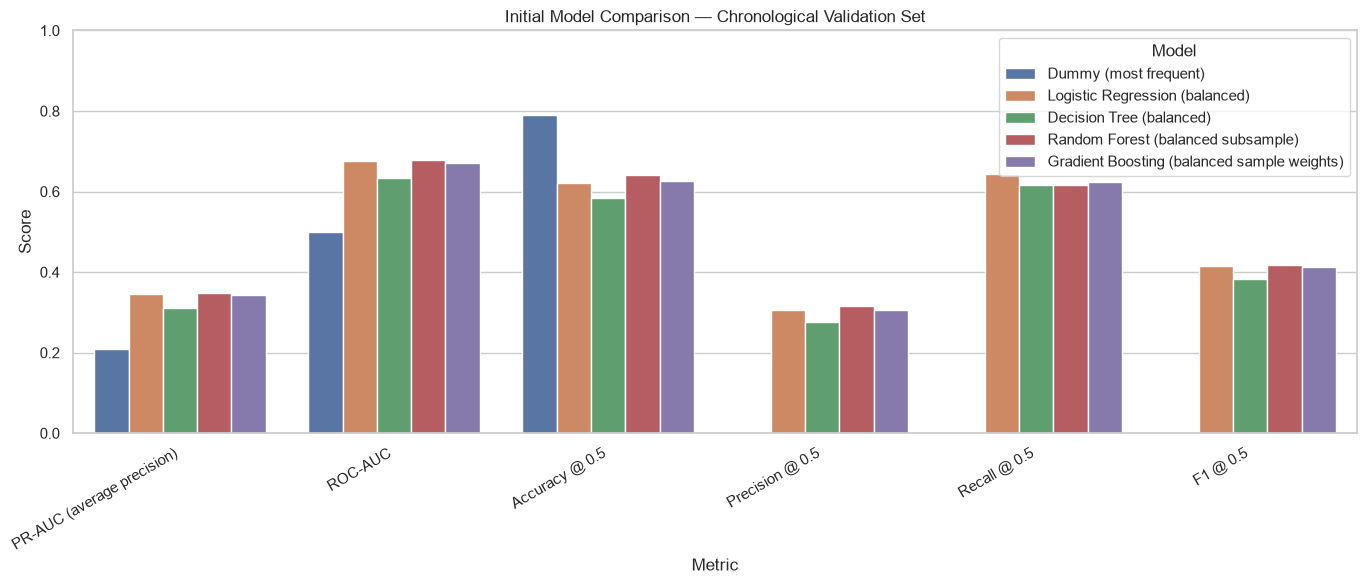

In [52]:
comparison_plot_df = comparison_df.reset_index().melt(
    id_vars=['Model'], var_name='Metric', value_name='Score',
)

plt.figure(figsize=(14, 6))
sns.barplot(data=comparison_plot_df, x='Metric', y='Score', hue='Model')
plt.title('Initial Model Comparison — Chronological Validation Set')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### Validation Interpretation and Summary

In the initial comparison, Random Forest had the highest validation PR-AUC among the untuned candidates (0.3471) and ROC-AUC 0.6772. Logistic Regression was close (PR-AUC 0.3463, ROC-AUC 0.6747); Gradient Boosting achieved PR-AUC 0.3421, and Decision Tree 0.3107. The Dummy Classifier had PR-AUC 0.2091 and ROC-AUC 0.5000; its 0.7909 accuracy comes from predicting only the majority class and its default recall is zero. These results support continued comparison but do not establish a final winner.

At the 0.5 threshold, Logistic Regression recall was 0.6445 and precision 0.3068; Random Forest recall was 0.6162 and precision 0.3157. This illustrates a modest ranking advantage for Random Forest alongside a slightly different operating trade-off. The threshold should be selected against business costs on validation data, not assumed to be optimal at 0.5. Validation has already supported candidate selection, so repeated experimentation can make its reported metrics optimistic. The final chronological test set must remain reserved for the final, single evaluation after decisions are frozen.

In [53]:
from pathlib import Path

if 'comparison_df' not in globals() or 'validation_confusion_matrices' not in globals():
    raise RuntimeError('Run the validation model-comparison cell before saving results.')

results_dir = Path('model_results')
results_dir.mkdir(parents=True, exist_ok=True)
comparison_path = results_dir / 'validation_model_comparison.csv'
comparison_df.to_csv(comparison_path, index=True)

confusion_paths = {}
for model_name, matrix in validation_confusion_matrices.items():
    safe_name = ''.join(char.lower() if char.isalnum() else '_' for char in model_name).strip('_')
    confusion_path = results_dir / f'{safe_name}_validation_confusion_matrix.csv'
    pd.DataFrame(
        matrix,
        index=['True Fully Paid (0)', 'True Default (1)'],
        columns=['Predicted Fully Paid (0)', 'Predicted Default (1)'],
    ).to_csv(confusion_path, index=True)
    confusion_paths[model_name] = confusion_path

print(f'Validation comparison saved to: {comparison_path.resolve()}')
print('Validation confusion matrices saved:')
for model_name, saved_path in confusion_paths.items():
    print(f'  {model_name}: {saved_path.resolve()}')
print('Best model by validation PR-AUC (average precision):')
display(comparison_df.sort_values('PR-AUC (average precision)', ascending=False))

Validation comparison saved to: /Users/minalghatge/Downloads/MS-BITS/Sem3/Apex_Project_2/Final Submission/model_results/validation_model_comparison.csv
Validation confusion matrices saved:
  Dummy (most frequent): /Users/minalghatge/Downloads/MS-BITS/Sem3/Apex_Project_2/Final Submission/model_results/dummy__most_frequent_validation_confusion_matrix.csv
  Logistic Regression (balanced): /Users/minalghatge/Downloads/MS-BITS/Sem3/Apex_Project_2/Final Submission/model_results/logistic_regression__balanced_validation_confusion_matrix.csv
  Decision Tree (balanced): /Users/minalghatge/Downloads/MS-BITS/Sem3/Apex_Project_2/Final Submission/model_results/decision_tree__balanced_validation_confusion_matrix.csv
  Random Forest (balanced subsample): /Users/minalghatge/Downloads/MS-BITS/Sem3/Apex_Project_2/Final Submission/model_results/random_forest__balanced_subsample_validation_confusion_matrix.csv
  Gradient Boosting (balanced sample weights): /Users/minalghatge/Downloads/MS-BITS/Sem3/Apex_Pro

,PR-AUC (average precision),ROC-AUC,Accuracy @ 0.5,Precision @ 0.5,Recall @ 0.5,F1 @ 0.5
Model,,,,,,
Random Forest (balanced subsample),0.3471,0.6772,0.6404,0.3157,0.6162,0.4175
Logistic Regression (balanced),0.3463,0.6747,0.6211,0.3068,0.6445,0.4157
Gradient Boosting (balanced sample weights),0.3421,0.6703,0.6271,0.3071,0.6233,0.4115
Decision Tree (balanced),0.3107,0.6340,0.5832,0.2770,0.6165,0.3822
Dummy (most frequent),0.2091,0.5000,0.7909,0.0000,0.0000,0.0000


## 8. Preliminary Hyperparameter Tuning

This first tuning experiment is intentionally small: it varies Logistic Regression regularization strength (`C` = 0.1, 1, 10) and a few Random Forest depth/minimum-leaf combinations. Other settings are held fixed to make the effect of these initial complexity choices easier to compare. Each candidate is fitted on the same model-training partition and scored on the same later validation partition. PR-AUC (average precision) is the primary ranking criterion because the positive default class is the minority; ROC-AUC is included as a secondary ranking measure.

The executed search selected Random Forest depth 12 with minimum leaf size 50 (120 trees for this tuning run), with validation PR-AUC 0.3474 and ROC-AUC 0.6773. The lift over the initial 250-tree Random Forest comparison (PR-AUC 0.3471) is very small, so it should not be treated as a decisive improvement. The search uses the validation set directly rather than cross-validation; therefore, its top score is a selection result and can be optimistic. The final-test data is not loaded into or evaluated by this tuning code.

In [54]:
from sklearn.base import clone

required_objects = ('baseline_model', 'train_encoded', 'validation_encoded', 'y_train', 'y_validation')
if not all(name in globals() for name in required_objects):
    raise RuntimeError('Run preprocessing and initial model comparison before tuning.')

# Compare a small set of regularization strengths and bounded forest configurations.
tuning_candidates = []
for c_value in [0.1, 1.0, 10.0]:
    tuning_candidates.append((
        f'Logistic Regression (C={c_value})',
        clone(baseline_model).set_params(logisticregression__C=c_value),
    ))

for max_depth, min_samples_leaf in [(8, 50), (12, 50), (12, 100)]:
    tuning_candidates.append((
        f'Random Forest (depth={max_depth}, leaf={min_samples_leaf})',
        RandomForestClassifier(
            n_estimators=120,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            max_features='sqrt',
            class_weight='balanced_subsample',
            n_jobs=-1,
            random_state=42,
        ),
    ))

tuning_rows = []
tuned_models = {}
for candidate_name, candidate_model in tuning_candidates:
    candidate_model.fit(train_encoded, y_train)
    probabilities = candidate_model.predict_proba(validation_encoded)[:, 1]
    tuning_rows.append({
        'Candidate': candidate_name,
        'PR-AUC (average precision)': average_precision_score(y_validation, probabilities),
        'ROC-AUC': roc_auc_score(y_validation, probabilities),
    })
    tuned_models[candidate_name] = candidate_model

tuning_results = pd.DataFrame(tuning_rows).sort_values(
    'PR-AUC (average precision)', ascending=False
).reset_index(drop=True)
print('Preliminary tuning results (ranked by validation PR-AUC):')
display(tuning_results.round(4))
selected_tuned_candidate = tuning_results.loc[0, 'Candidate']
print(f'Highest validation PR-AUC candidate in this small search: {selected_tuned_candidate}')
print('The final-test set was not used for tuning. These validation scores are selection results, not final estimates.')

Preliminary tuning results (ranked by validation PR-AUC):


,Candidate,PR-AUC (average precision),ROC-AUC
0,"Random Forest (depth=12, leaf=50)",0.3474,0.6773
1,Logistic Regression (C=10.0),0.3464,0.6748
2,Logistic Regression (C=0.1),0.3464,0.6748
3,Logistic Regression (C=1.0),0.3463,0.6747
4,"Random Forest (depth=12, leaf=100)",0.3449,0.6754
5,"Random Forest (depth=8, leaf=50)",0.3436,0.6726


Highest validation PR-AUC candidate in this small search: Random Forest (depth=12, leaf=50)
The final-test set was not used for tuning. These validation scores are selection results, not final estimates.


## 9. Preliminary Evaluation and Interpretation

The current results establish useful baselines, but performance is moderate and model differences are small. The best untuned comparison candidate, Random Forest, reached validation PR-AUC 0.3471 and ROC-AUC 0.6772; the tuned small-grid candidate reached PR-AUC 0.3474 and ROC-AUC 0.6773. Logistic Regression remains competitive and more interpretable. At the default threshold, both balanced classifiers identify a substantial share of defaults but produce many false positives, as reflected in precision near 0.31. Accuracy is not a sufficient selection metric: the Dummy model reaches 0.7909 accuracy while detecting no defaults.

Interpretation is limited by the single chronological validation interval, repeated validation-based model selection, the dataset’s historical period, the outcome’s variable follow-up time, and the initial exclusion of high-cardinality categorical predictors. The 0.5 threshold has not been optimized for a stated business cost. No tuning or model selection has used the final test months; keep them untouched until the model, preprocessing, and decision threshold are frozen, then report the final test results separately.

In [55]:
if 'comparison_df' not in globals() or 'tuning_results' not in globals():
    raise RuntimeError('Run initial model comparison and preliminary tuning first.')

print('Initial validation comparison (threshold metrics use 0.5):')
display(comparison_df.sort_values('PR-AUC (average precision)', ascending=False))

initial_best_name = comparison_df['PR-AUC (average precision)'].idxmax()
initial_best_pr_auc = comparison_df.loc[initial_best_name, 'PR-AUC (average precision)']
baseline_pr_auc = comparison_df.loc['Logistic Regression (balanced)', 'PR-AUC (average precision)']
tuned_best = tuning_results.iloc[0]
print(f'Initial comparison leader: {initial_best_name} (PR-AUC={initial_best_pr_auc:.4f})')
print(f'Logistic Regression baseline PR-AUC: {baseline_pr_auc:.4f}')
print(
    f"Top candidate in limited tuning search: {tuned_best['Candidate']} "
    f"(validation PR-AUC={tuned_best['PR-AUC (average precision)']:.4f}, "
    f"ROC-AUC={tuned_best['ROC-AUC']:.4f})"
)

print('Interpretation and limitations:')
for item in [
    'The Dummy Classifier provides a no-skill reference; its high accuracy reflects class imbalance, not useful default detection.',
    'PR-AUC and recall help assess default detection; precision and F1 describe the false-alarm trade-off.',
    'A 0.5 threshold is only a reference; select any operating threshold using validation data and business costs.',
    'Repeated model selection on validation can make the reported validation scores optimistic.',
    'The final chronological test period has not been used for fitting, tuning, or selection.',
    'The target is the recorded resolved status in this historical snapshot and does not represent a fixed-horizon default outcome.',
]:
    print(f'- {item}')

Initial validation comparison (threshold metrics use 0.5):


,PR-AUC (average precision),ROC-AUC,Accuracy @ 0.5,Precision @ 0.5,Recall @ 0.5,F1 @ 0.5
Model,,,,,,
Random Forest (balanced subsample),0.3471,0.6772,0.6404,0.3157,0.6162,0.4175
Logistic Regression (balanced),0.3463,0.6747,0.6211,0.3068,0.6445,0.4157
Gradient Boosting (balanced sample weights),0.3421,0.6703,0.6271,0.3071,0.6233,0.4115
Decision Tree (balanced),0.3107,0.6340,0.5832,0.2770,0.6165,0.3822
Dummy (most frequent),0.2091,0.5000,0.7909,0.0000,0.0000,0.0000


Initial comparison leader: Random Forest (balanced subsample) (PR-AUC=0.3471)
Logistic Regression baseline PR-AUC: 0.3463
Top candidate in limited tuning search: Random Forest (depth=12, leaf=50) (validation PR-AUC=0.3474, ROC-AUC=0.6773)
Interpretation and limitations:
- The Dummy Classifier provides a no-skill reference; its high accuracy reflects class imbalance, not useful default detection.
- PR-AUC and recall help assess default detection; precision and F1 describe the false-alarm trade-off.
- A 0.5 threshold is only a reference; select any operating threshold using validation data and business costs.
- Repeated model selection on validation can make the reported validation scores optimistic.
- The final chronological test period has not been used for fitting, tuning, or selection.
- The target is the recorded resolved status in this historical snapshot and does not represent a fixed-horizon default outcome.


## 10. Overfitting / Generalization Discussion

This section compares each fitted model's training performance with its chronological validation performance. A large PR-AUC or ROC-AUC gap, or a much stronger training F1/accuracy than validation F1/accuracy, may indicate overfitting or instability across the time split.

The interpretation below is a diagnostic rather than a claim that the observed gap is statistically significant. Differences can also reflect temporal distribution shift, class imbalance, or the use of a fixed 0.5 threshold. The final chronological test period is not used in this discussion.


Training-versus-validation behavior (threshold = 0.5):


,Train PR-AUC,Validation PR-AUC,PR-AUC gap,Train ROC-AUC,Validation ROC-AUC,ROC-AUC gap,Train F1 @ 0.5,Validation F1 @ 0.5,F1 gap,Train accuracy,Validation accuracy,Validation recall,Validation precision
Model,,,,,,,,,,,,,
"Tuned: Random Forest (depth=12, leaf=50)",0.3887,0.3474,0.0413,0.7384,0.6773,0.0611,0.4313,0.4167,0.0146,0.7033,0.6403,0.6145,0.3153
Random Forest (balanced subsample),0.3894,0.3471,0.0423,0.7388,0.6772,0.0616,0.4315,0.4175,0.0139,0.7033,0.6404,0.6162,0.3157
Tuned: Logistic Regression (C=10.0),0.3300,0.3464,-0.0164,0.6886,0.6748,0.0138,0.3885,0.4158,-0.0273,0.6501,0.6214,0.6443,0.3069
Tuned: Logistic Regression (C=0.1),0.3300,0.3464,-0.0164,0.6886,0.6748,0.0138,0.3885,0.4160,-0.0275,0.6499,0.6214,0.6447,0.3070
Logistic Regression (balanced),0.3300,0.3463,-0.0163,0.6886,0.6747,0.0139,0.3882,0.4157,-0.0275,0.6497,0.6211,0.6445,0.3068
Tuned: Logistic Regression (C=1.0),0.3300,0.3463,-0.0163,0.6886,0.6747,0.0139,0.3882,0.4157,-0.0275,0.6497,0.6211,0.6445,0.3068
"Tuned: Random Forest (depth=12, leaf=100)",0.3647,0.3449,0.0198,0.7225,0.6754,0.0471,0.4166,0.4166,0.0001,0.6857,0.6287,0.6338,0.3102
"Tuned: Random Forest (depth=8, leaf=50)",0.3467,0.3436,0.0030,0.7015,0.6726,0.0289,0.3989,0.4133,-0.0144,0.6852,0.6313,0.6209,0.3097
Gradient Boosting (balanced sample weights),0.3267,0.3421,-0.0153,0.6857,0.6703,0.0154,0.3846,0.4115,-0.0269,0.6620,0.6271,0.6233,0.3071


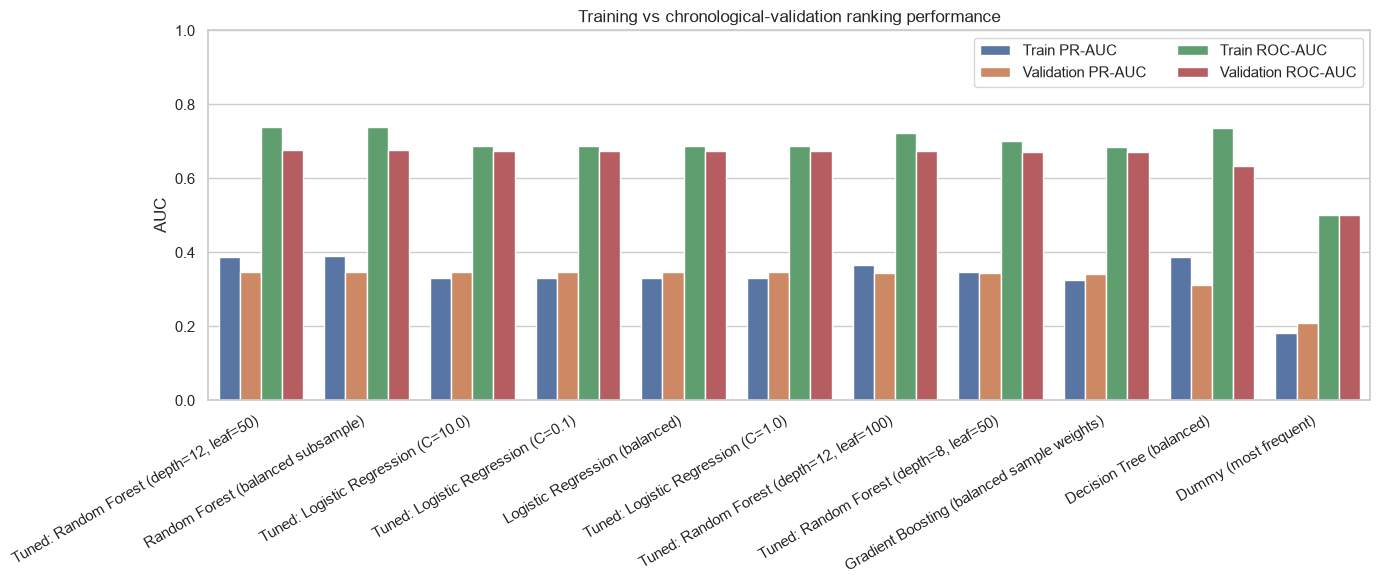

Largest training-minus-validation PR-AUC gap: Decision Tree (balanced) (0.0773)
Best validation PR-AUC candidate: Tuned: Random Forest (depth=12, leaf=50) (train=0.3887, validation=0.3474, gap=0.0413)
Generalization interpretation:
- A positive PR-AUC or ROC-AUC gap indicates better in-sample ranking than chronological out-of-sample ranking.
- A small gap supports generalization, but it does not eliminate temporal shift or repeated-validation selection bias.
- A large F1 gap at 0.5 should be considered together with precision and recall rather than interpreted alone.
- Tree and ensemble models may show larger apparent gaps because they have greater fitting capacity.
- The final chronological test partition remains untouched and must be evaluated only after the model and threshold are frozen.


In [56]:
# Training-versus-validation overfitting / generalization analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, average_precision_score, f1_score,
    precision_score, recall_score, roc_auc_score,
)

required_objects = (
    'train_encoded', 'validation_encoded', 'y_train', 'y_validation',
    'validation_models',
)
if not all(name in globals() for name in required_objects):
    raise RuntimeError('Run the initial model-comparison cell before this generalization check.')

candidate_models = {}
candidate_models.update(validation_models)
if 'tuned_models' in globals():
    for name, model in tuned_models.items():
        candidate_models[f'Tuned: {name}'] = model

behavior_rows = []
for model_name, model in candidate_models.items():
    train_probabilities = model.predict_proba(train_encoded)[:, 1]
    validation_probabilities = model.predict_proba(validation_encoded)[:, 1]

    train_predictions = (train_probabilities >= 0.5).astype('int8')
    validation_predictions = (validation_probabilities >= 0.5).astype('int8')

    behavior_rows.append({
        'Model': model_name,
        'Train PR-AUC': average_precision_score(y_train, train_probabilities),
        'Validation PR-AUC': average_precision_score(y_validation, validation_probabilities),
        'PR-AUC gap': average_precision_score(y_train, train_probabilities)
                       - average_precision_score(y_validation, validation_probabilities),
        'Train ROC-AUC': roc_auc_score(y_train, train_probabilities),
        'Validation ROC-AUC': roc_auc_score(y_validation, validation_probabilities),
        'ROC-AUC gap': roc_auc_score(y_train, train_probabilities)
                       - roc_auc_score(y_validation, validation_probabilities),
        'Train F1 @ 0.5': f1_score(y_train, train_predictions, zero_division=0),
        'Validation F1 @ 0.5': f1_score(y_validation, validation_predictions, zero_division=0),
        'F1 gap': f1_score(y_train, train_predictions, zero_division=0)
                  - f1_score(y_validation, validation_predictions, zero_division=0),
        'Train accuracy': accuracy_score(y_train, train_predictions),
        'Validation accuracy': accuracy_score(y_validation, validation_predictions),
        'Validation recall': recall_score(y_validation, validation_predictions, zero_division=0),
        'Validation precision': precision_score(y_validation, validation_predictions, zero_division=0),
    })

generalization_df = pd.DataFrame(behavior_rows).set_index('Model').sort_values(
    'Validation PR-AUC', ascending=False
)

print('Training-versus-validation behavior (threshold = 0.5):')
display(generalization_df.round(4))

plot_df = generalization_df.reset_index().melt(
    id_vars=['Model'],
    value_vars=['Train PR-AUC', 'Validation PR-AUC', 'Train ROC-AUC', 'Validation ROC-AUC'],
    var_name='Metric',
    value_name='Score',
)
plt.figure(figsize=(14, 6))
import seaborn as sns
sns.barplot(data=plot_df, x='Model', y='Score', hue='Metric')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 1)
plt.title('Training vs chronological-validation ranking performance')
plt.ylabel('AUC')
plt.xlabel('')
plt.legend(title='', ncol=2)
plt.tight_layout()
plt.show()

strongest_gap = generalization_df['PR-AUC gap'].idxmax()
strongest_gap_value = generalization_df.loc[strongest_gap, 'PR-AUC gap']
print(f'Largest training-minus-validation PR-AUC gap: {strongest_gap} ({strongest_gap_value:.4f})')

best_validation_name = generalization_df['Validation PR-AUC'].idxmax()
best_validation_row = generalization_df.loc[best_validation_name]
print(
    f"Best validation PR-AUC candidate: {best_validation_name} "
    f"(train={best_validation_row['Train PR-AUC']:.4f}, "
    f"validation={best_validation_row['Validation PR-AUC']:.4f}, "
    f"gap={best_validation_row['PR-AUC gap']:.4f})"
)

print('Generalization interpretation:')
for item in [
    'A positive PR-AUC or ROC-AUC gap indicates better in-sample ranking than chronological out-of-sample ranking.',
    'A small gap supports generalization, but it does not eliminate temporal shift or repeated-validation selection bias.',
    'A large F1 gap at 0.5 should be considered together with precision and recall rather than interpreted alone.',
    'Tree and ensemble models may show larger apparent gaps because they have greater fitting capacity.',
    'The final chronological test partition remains untouched and must be evaluated only after the model and threshold are frozen.',
]:
    print(f'- {item}')


## 11. Implemented Improvements

This section executes the planned improvements while keeping model selection and preprocessing decisions inside the development period. The newest chronological test period is reserved for one final scoring pass after every development choice is frozen. Earlier cells may prepare its predictors using training-fitted transformations, but its outcomes do not guide model or threshold selection.

Each subsection below has one responsibility:

1. temporal validation setup,
2. fold-safe preprocessing,
3. controlled candidate comparison,
4. threshold and calibration analysis,
5. monthly robustness checks,
6. the single final held-out test evaluation,
7. an implementation-status summary.


### 11.1 Expanding-Window Temporal Validation Setup

Cross-validation uses only the model-training partition. The separate chronological validation partition is held out for threshold selection and calibration, and the final chronological test partition is excluded from all development choices.

Three disjoint, later month blocks within model-training data are scored. For each block, the model is fit on all earlier model-training months. This expanding-window design grows the training history over time without training on future observations.


In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

required_objects = (
    'train_df', 'validation_df', 'test_df', 'train_clean', 'validation_clean',
    'test_clean', 'y_train', 'y_validation', 'y_test',
    'metadata_identifiers', 'post_decision_cols', 'leakage_cols',
    'parse_text_features', 'add_application_features',
)
if not all(name in globals() for name in required_objects):
    raise RuntimeError('Run Sections 2-9 before executing the implemented improvements.')

# Development data excludes the final chronological test partition.
# Cross-validation is restricted to model-training months; validation remains separate.
development_raw = train_df.copy()
development_raw = parse_text_features(development_raw)
development_raw = add_application_features(development_raw)
development_raw = development_raw.drop(
    columns=metadata_identifiers + post_decision_cols + leakage_cols,
    errors='ignore',
)

issue_dates = pd.to_datetime(development_raw['issue_d'], format='%b-%y', errors='coerce')
if issue_dates.isna().any():
    raise ValueError('Development issue_month values contain an invalid month.')
development_raw['_issue_period'] = issue_dates.dt.to_period('M')
issue_periods = sorted(development_raw['_issue_period'].unique())

if len(issue_periods) < 8:
    raise ValueError('At least eight development months are needed for expanding-window validation.')

cut_positions = [int(0.70 * len(issue_periods)), int(0.80 * len(issue_periods)), int(0.90 * len(issue_periods))]
validation_end_positions = [int(0.80 * len(issue_periods)), int(0.90 * len(issue_periods)), len(issue_periods)]
cv_splits = []

for cut, validation_end in zip(cut_positions, validation_end_positions):
    cut = min(cut, len(issue_periods) - 1)
    validation_end = max(cut + 1, min(validation_end, len(issue_periods)))
    train_periods = issue_periods[:cut]
    validation_periods = issue_periods[cut:validation_end]

    train_index = development_raw['_issue_period'].isin(train_periods)
    validation_index = development_raw['_issue_period'].isin(validation_periods)
    y_fold_train = development_raw.loc[train_index, 'target'].astype('int8').to_numpy()
    y_fold_validation = development_raw.loc[validation_index, 'target'].astype('int8').to_numpy()

    if (train_index.sum() == 0 or validation_index.sum() == 0
            or len(np.unique(y_fold_train)) < 2 or len(np.unique(y_fold_validation)) < 2):
        continue

    cv_splits.append((train_index, validation_index))

if not cv_splits:
    raise RuntimeError('No usable expanding-window development folds were created.')

print(f'Development months: {len(issue_periods)}')
print(f'Usable expanding-window folds: {len(cv_splits)}')
for fold_number, (train_index, validation_index) in enumerate(cv_splits, start=1):
    train_months = development_raw.loc[train_index, '_issue_period']
    validation_months = development_raw.loc[validation_index, '_issue_period']
    print(
        f'Fold {fold_number}: train={train_months.min()} to {train_months.max()}, '
        f'validation={validation_months.min()} to {validation_months.max()}'
    )


Development months: 77
Usable expanding-window folds: 3
Fold 1: train=2007-06 to 2011-10, validation=2011-11 to 2012-06
Fold 2: train=2007-06 to 2012-06, validation=2012-07 to 2013-02
Fold 3: train=2007-06 to 2013-02, validation=2013-03 to 2013-10


### 11.2 Fold-Safe Preprocessing and Feature Representation

The >80% missingness filter, imputation, percentile capping, and categorical encoding are learned inside each training fold rather than from the complete development period. This prevents information from the fold validation block from entering preprocessing.

The original `issue_d` field is excluded from predictors because it is a temporal partition identifier, not an application feature. The representation comparison tests:

- low-cardinality one-hot encoding only; and
- low-cardinality one-hot encoding plus deterministic 32-bucket hashing for high-cardinality categories.


In [58]:
def prepare_fold(frame_train, frame_validation, hashed_categories=False):
    """Fit imputation, capping, and encoding only on the fold training rows."""
    fold_train = frame_train.drop(
        columns=['target', 'loan_status', '_issue_period', 'issue_d'],
        errors='ignore',
    ).copy()
    fold_validation = frame_validation.drop(
        columns=['target', 'loan_status', '_issue_period', 'issue_d'],
        errors='ignore',
    ).copy()

    high_missingness_cols = fold_train.columns[
        fold_train.isna().mean() > 0.80
    ].tolist()
    fold_train = fold_train.drop(columns=high_missingness_cols, errors='ignore')
    fold_validation = fold_validation.drop(columns=high_missingness_cols, errors='ignore')

    numeric_cols = fold_train.select_dtypes(include='number').columns.tolist()
    categorical_cols = [
        col for col in fold_train.columns
        if pd.api.types.is_object_dtype(fold_train[col])
        or pd.api.types.is_string_dtype(fold_train[col])
        or isinstance(fold_train[col].dtype, pd.CategoricalDtype)
    ]

    numeric_medians = fold_train[numeric_cols].median()
    all_missing_numeric_cols = numeric_medians[numeric_medians.isna()].index.tolist()
    if all_missing_numeric_cols:
        fold_train = fold_train.drop(columns=all_missing_numeric_cols)
        fold_validation = fold_validation.drop(columns=all_missing_numeric_cols)
        numeric_cols = numeric_medians[numeric_medians.notna()].index.tolist()
    for col in numeric_cols:
        fold_train[col] = fold_train[col].fillna(numeric_medians[col])
        fold_validation[col] = fold_validation[col].fillna(numeric_medians[col])

    for col in categorical_cols:
        modes = fold_train[col].mode()
        fill_value = modes.iloc[0] if not modes.empty else '__missing__'
        fold_train[col] = fold_train[col].fillna(fill_value).astype('string')
        fold_validation[col] = fold_validation[col].fillna(fill_value).astype('string')

    for col in numeric_cols:
        if fold_train[col].nunique(dropna=True) <= 2:
            continue
        lower = fold_train[col].quantile(0.01)
        upper = fold_train[col].quantile(0.99)
        if pd.isna(lower) or pd.isna(upper) or lower >= upper:
            continue
        fold_train[col] = fold_train[col].clip(lower=lower, upper=upper)
        fold_validation[col] = fold_validation[col].clip(lower=lower, upper=upper)

    low_card_cols = [
        col for col in categorical_cols
        if fold_train[col].nunique(dropna=True) <= 15
    ]
    high_card_cols = [col for col in categorical_cols if col not in low_card_cols]

    train_encoded_fold = pd.get_dummies(
        fold_train.drop(columns=high_card_cols),
        columns=low_card_cols, drop_first=False, dtype='int8'
    )
    validation_encoded_fold = pd.get_dummies(
        fold_validation.drop(columns=high_card_cols),
        columns=low_card_cols, drop_first=False, dtype='int8'
    )

    if hashed_categories:
        train_hash_buckets = {
            col: pd.util.hash_pandas_object(fold_train[col], index=False).mod(32)
            for col in high_card_cols
        }
        validation_hash_buckets = {
            col: pd.util.hash_pandas_object(fold_validation[col], index=False).mod(32)
            for col in high_card_cols
        }
        for col in high_card_cols:
            for bucket in range(32):
                train_encoded_fold[f'{col}__hash_{bucket}'] = (
                    train_hash_buckets[col] == bucket
                ).astype('int8')
                validation_encoded_fold[f'{col}__hash_{bucket}'] = (
                    validation_hash_buckets[col] == bucket
                ).astype('int8')

    validation_encoded_fold = validation_encoded_fold.reindex(
        columns=train_encoded_fold.columns, fill_value=0
    )
    return train_encoded_fold, validation_encoded_fold


### 11.3 Controlled Model and Representation Search

The search is intentionally bounded to avoid using compute and repeated validation choices as an advantage that does not translate to future data.

Both representations use the same four candidates: three Logistic Regression regularization strengths and one bounded Random Forest configuration. Candidate selection uses only the expanding-window folds within model-training months. Within every fold, preprocessing is refitted and its later block is scored once.


In [59]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, roc_auc_score

logistic_regularization = [0.1, 1.0, 10.0]
cv_rows = []

for hashed_categories in [False, True]:
    representation = (
        'Low-cardinality only'
        if not hashed_categories
        else 'Low-cardinality + hashed categories'
    )

    for c_value in logistic_regularization:
        fold_metrics = []
        for train_index, validation_index in cv_splits:
            X_fold_train, X_fold_validation = prepare_fold(
                development_raw.loc[train_index],
                development_raw.loc[validation_index],
                hashed_categories=hashed_categories,
            )
            y_fold_train = development_raw.loc[train_index, 'target'].astype('int8').to_numpy()
            y_fold_validation = development_raw.loc[validation_index, 'target'].astype('int8').to_numpy()

            continuous_features = [
                col for col in X_fold_train.columns
                if X_fold_train[col].nunique(dropna=True) > 2
            ]
            model = make_pipeline(
                ColumnTransformer(
                    [('scale', StandardScaler(), continuous_features)],
                    remainder='passthrough',
                    verbose_feature_names_out=False,
                ),
                LogisticRegression(
                    C=c_value, class_weight='balanced', max_iter=500,
                    random_state=42,
                ),
            )
            model.fit(X_fold_train, y_fold_train)
            probabilities = model.predict_proba(X_fold_validation)[:, 1]
            fold_metrics.append((
                average_precision_score(y_fold_validation, probabilities),
                roc_auc_score(y_fold_validation, probabilities),
            ))

        cv_rows.append({
            'Representation': representation,
            'Candidate': f'Logistic C={c_value}',
            'Mean CV PR-AUC': np.mean([m[0] for m in fold_metrics]),
            'Mean CV ROC-AUC': np.mean([m[1] for m in fold_metrics]),
            'Fold PR-AUC': ', '.join(f'{m[0]:.4f}' for m in fold_metrics),
        })

    fold_metrics = []
    for train_index, validation_index in cv_splits:
        X_fold_train, X_fold_validation = prepare_fold(
            development_raw.loc[train_index],
            development_raw.loc[validation_index],
            hashed_categories=hashed_categories,
        )
        y_fold_train = development_raw.loc[train_index, 'target'].astype('int8').to_numpy()
        y_fold_validation = development_raw.loc[validation_index, 'target'].astype('int8').to_numpy()

        model = RandomForestClassifier(
            n_estimators=80, max_depth=12, min_samples_leaf=50,
            class_weight='balanced_subsample', n_jobs=-1, random_state=42,
        )
        model.fit(X_fold_train, y_fold_train)
        probabilities = model.predict_proba(X_fold_validation)[:, 1]
        fold_metrics.append((
            average_precision_score(y_fold_validation, probabilities),
            roc_auc_score(y_fold_validation, probabilities),
        ))

    cv_rows.append({
        'Representation': representation,
        'Candidate': 'Random Forest depth=12',
        'Mean CV PR-AUC': np.mean([m[0] for m in fold_metrics]),
        'Mean CV ROC-AUC': np.mean([m[1] for m in fold_metrics]),
        'Fold PR-AUC': ', '.join(f'{m[0]:.4f}' for m in fold_metrics),
    })

cv_results = pd.DataFrame(cv_rows).sort_values(
    ['Mean CV PR-AUC', 'Mean CV ROC-AUC'], ascending=False
).reset_index(drop=True)

print('Expanding-window development CV:')
display(cv_results.round(4))

best_row = cv_results.iloc[0]
print(f"Highest mean development PR-AUC: {best_row['Candidate']} with {best_row['Representation']}")


/var/folders/mv/nknd0jw94b9cxcn3_gl663t80000gn/T/ipykernel_6191/1038768880.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_encoded_fold[f'{col}__hash_{bucket}'] = (
/var/folders/mv/nknd0jw94b9cxcn3_gl663t80000gn/T/ipykernel_6191/1038768880.py:81: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  validation_encoded_fold[f'{col}__hash_{bucket}'] = (
/var/folders/mv/nknd0jw94b9cxcn3_gl663t80000gn/T/ipykernel_6191/1038768880.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `fra

Expanding-window development CV:


,Representation,Candidate,Mean CV PR-AUC,Mean CV ROC-AUC,Fold PR-AUC
0,Low-cardinality only,Logistic C=0.1,0.3357,0.6816,"0.3522, 0.3022, 0.3528"
1,Low-cardinality only,Logistic C=1.0,0.3356,0.6816,"0.3521, 0.3020, 0.3528"
2,Low-cardinality only,Logistic C=10.0,0.3356,0.6815,"0.3521, 0.3019, 0.3527"
3,Low-cardinality only,Random Forest depth=12,0.3318,0.6795,"0.3473, 0.2984, 0.3496"
4,Low-cardinality + hashed categories,Random Forest depth=12,0.3300,0.6772,"0.3454, 0.2978, 0.3468"
5,Low-cardinality + hashed categories,Logistic C=0.1,0.3286,0.6768,"0.3357, 0.2975, 0.3527"
6,Low-cardinality + hashed categories,Logistic C=1.0,0.3279,0.6762,"0.3345, 0.2968, 0.3525"
7,Low-cardinality + hashed categories,Logistic C=10.0,0.3278,0.6761,"0.3343, 0.2966, 0.3526"


Highest mean development PR-AUC: Logistic C=0.1 with Low-cardinality only


### 11.4 Development Threshold and Calibration Analysis

The candidate and feature representation are selected using expanding-window scores from model-training months. The separate chronological validation period is used for threshold selection and calibration, not CV candidate ranking. Sections 7-9 already show validation comparisons and preliminary tuning, so some validation-selection optimism remains possible.

The threshold is the value among the validation precision-recall candidates that maximizes validation F1. Maximizing F1 is a transparent starting point, not proof of the financially correct operating point. Probability calibration and Brier score are reported to assess whether probabilities can be interpreted as risk estimates.


Development-selected threshold: 0.5132
Development threshold metrics:


,PR-AUC,ROC-AUC,Precision,Recall,F1,Brier score
Logistic C=0.1,0.3464,0.6748,0.3149,0.6176,0.4171,0.2341


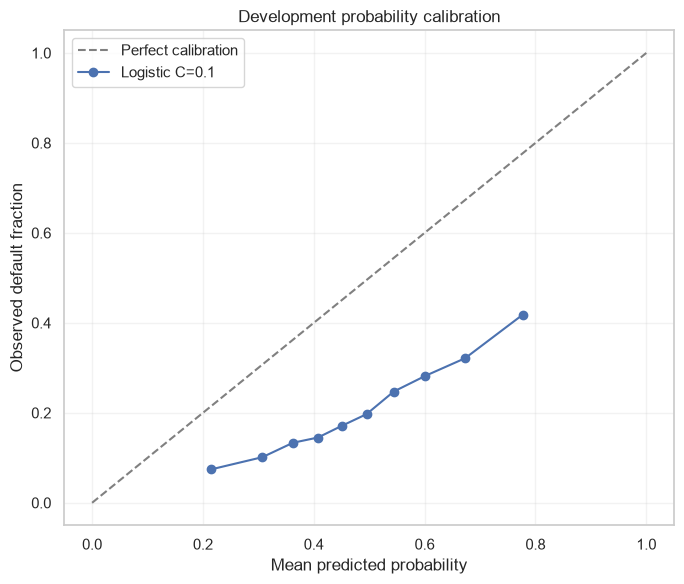

In [60]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    brier_score_loss, confusion_matrix, f1_score, precision_recall_curve,
    precision_score, recall_score,
)

selected_name = best_row['Candidate']
hashed_selected = 'hashed categories' in str(best_row['Representation'])

selected_train_raw = development_raw.copy()
selected_validation_raw = parse_text_features(validation_df.copy())
selected_validation_raw = add_application_features(selected_validation_raw)
selected_validation_raw = selected_validation_raw.drop(
    columns=metadata_identifiers + post_decision_cols + leakage_cols,
    errors='ignore',
)
validation_dates_for_model = pd.to_datetime(
    selected_validation_raw['issue_d'], format='%b-%y', errors='coerce'
)
if validation_dates_for_model.isna().any():
    raise ValueError('Validation issue_month values contain an invalid month.')
selected_validation_raw['_issue_period'] = validation_dates_for_model.dt.to_period('M')
if selected_train_raw['_issue_period'].max() >= selected_validation_raw['_issue_period'].min():
    raise AssertionError('Model-training and validation periods overlap.')

selected_train_encoded, selected_validation_encoded = prepare_fold(
    selected_train_raw,
    selected_validation_raw,
    hashed_categories=hashed_selected,
)
y_selected_train = selected_train_raw['target'].astype('int8').to_numpy()
y_selected_validation = selected_validation_raw['target'].astype('int8').to_numpy()

if selected_name.startswith('Logistic'):
    c_value = float(selected_name.split('C=')[1])
    continuous_features = [
        col for col in selected_train_encoded.columns
        if selected_train_encoded[col].nunique(dropna=True) > 2
    ]
    selected_model = make_pipeline(
        ColumnTransformer(
            [('scale', StandardScaler(), continuous_features)],
            remainder='passthrough',
            verbose_feature_names_out=False,
        ),
        LogisticRegression(
            C=c_value, class_weight='balanced', max_iter=1000,
            random_state=42,
        ),
    )
else:
    selected_model = RandomForestClassifier(
        n_estimators=80, max_depth=12, min_samples_leaf=50,
        class_weight='balanced_subsample', n_jobs=-1, random_state=42,
    )

selected_model.fit(selected_train_encoded, y_selected_train)
validation_probabilities = selected_model.predict_proba(selected_validation_encoded)[:, 1]

precision_curve, recall_curve, thresholds = precision_recall_curve(
    y_selected_validation, validation_probabilities
)
f1_scores = 2 * (precision_curve[:-1] * recall_curve[:-1]) / (
    precision_curve[:-1] + recall_curve[:-1] + 1e-12
)
chosen_threshold = float(thresholds[int(np.argmax(f1_scores))])
chosen_threshold = float(np.clip(chosen_threshold, 0.0, 1.0))

validation_predictions = (
    validation_probabilities >= chosen_threshold
).astype('int8')

development_threshold_metrics = pd.DataFrame([{
    'PR-AUC': average_precision_score(y_selected_validation, validation_probabilities),
    'ROC-AUC': roc_auc_score(y_selected_validation, validation_probabilities),
    'Precision': precision_score(y_selected_validation, validation_predictions, zero_division=0),
    'Recall': recall_score(y_selected_validation, validation_predictions, zero_division=0),
    'F1': f1_score(y_selected_validation, validation_predictions, zero_division=0),
    'Brier score': brier_score_loss(y_selected_validation, validation_probabilities),
}], index=[selected_name]).round(4)

print(f'Development-selected threshold: {chosen_threshold:.4f}')
print('Development threshold metrics:')
display(development_threshold_metrics)

cal_fraction, cal_mean = calibration_curve(
    y_selected_validation, validation_probabilities,
    n_bins=10, strategy='quantile',
)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
ax.plot(cal_mean, cal_fraction, marker='o', label=selected_name)
ax.set(
    title='Development probability calibration',
    xlabel='Mean predicted probability',
    ylabel='Observed default fraction',
)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


### 11.5 Issue-Month Robustness and Responsible-Use Checks

The validation-period predictions are summarized by month. Each cohort is displayed only if it contains at least 100 loans and both target classes, preventing a very small or one-class month from being interpreted as stable performance.

These checks detect temporal differences; they do not establish causation or fairness. Approved sensitive attributes, policy context, feature availability, and historical data limitations would be required before responsible group-fairness conclusions.


In [61]:
validation_cohort = selected_validation_raw.copy()
validation_cohort['_probability'] = validation_probabilities
validation_cohort['_month'] = validation_cohort['_issue_period'].astype(str)

cohort_rows = []
for month, group in validation_cohort.groupby('_month'):
    if len(group) >= 100 and group['target'].nunique() == 2:
        cohort_rows.append({
            'Cohort': month,
            'Rows': len(group),
            'PR-AUC': average_precision_score(
                group['target'], group['_probability']
            ),
            'ROC-AUC': roc_auc_score(
                group['target'], group['_probability']
            ),
        })

cohort_table = pd.DataFrame(cohort_rows).sort_values('Cohort')
print('Validation-period performance by issue month (development only):')
if cohort_table.empty:
    display(pd.DataFrame([{
        'Status': 'No month cohort had at least 100 rows and both classes'
    }]))
else:
    display(cohort_table.round(4))


Validation-period performance by issue month (development only):


,Cohort,Rows,PR-AUC,ROC-AUC
0,2013-11,6665,0.3360,0.6730
1,2013-12,6644,0.3251,0.6783
2,2014-01,6522,0.3197,0.6617
3,2014-02,5907,0.3747,0.6797
4,2014-03,6191,0.3531,0.6768
5,2014-04,6744,0.3730,0.6786


### 11.6 Frozen Final Held-Out Evaluation

Only after the representation, candidate, preprocessing approach, and threshold are fixed, the final chronological test period is scored once.

The test features use the preprocessing transformation fitted on the selected model-training rows. No final-test probabilities or metrics influence a further model or threshold change. The held-out metrics therefore should be reported as the project’s final result without additional tuning.


In [62]:
raw_test_for_evaluation = parse_text_features(
    test_df.drop(columns=['target', 'loan_status'], errors='ignore').copy()
)
raw_test_for_evaluation = add_application_features(raw_test_for_evaluation)
raw_test_for_evaluation = raw_test_for_evaluation.drop(
    columns=metadata_identifiers + post_decision_cols + leakage_cols,
    errors='ignore',
)

_, selected_test_encoded = prepare_fold(
    selected_train_raw,
    raw_test_for_evaluation,
    hashed_categories=hashed_selected,
)

selected_model.fit(selected_train_encoded, y_selected_train)
test_probabilities = selected_model.predict_proba(selected_test_encoded)[:, 1]
test_predictions = (test_probabilities >= chosen_threshold).astype('int8')

y_frozen_test = test_df['target'].astype('int8').to_numpy()
final_test_metrics = pd.DataFrame([{
    'PR-AUC': average_precision_score(y_frozen_test, test_probabilities),
    'ROC-AUC': roc_auc_score(y_frozen_test, test_probabilities),
    'Accuracy': (test_predictions == y_frozen_test).mean(),
    'Precision': precision_score(y_frozen_test, test_predictions, zero_division=0),
    'Recall': recall_score(y_frozen_test, test_predictions, zero_division=0),
    'F1': f1_score(y_frozen_test, test_predictions, zero_division=0),
}], index=['Frozen final model']).round(4)

print('Single final held-out test evaluation:')
display(final_test_metrics)
print('Final-test confusion matrix (rows=true, columns=predicted; labels 0, 1):')
display(pd.DataFrame(
    confusion_matrix(y_frozen_test, test_predictions, labels=[0, 1]),
    index=['True Fully Paid (0)', 'True Default (1)'],
    columns=['Predicted Fully Paid (0)', 'Predicted Default (1)'],
))


Single final held-out test evaluation:


,PR-AUC,ROC-AUC,Accuracy,Precision,Recall,F1
Frozen final model,0.3607,0.6911,0.6262,0.3127,0.6585,0.4241


Final-test confusion matrix (rows=true, columns=predicted; labels 0, 1):


,Predicted Fully Paid (0),Predicted Default (1)
True Fully Paid (0),21471,13289
True Default (1),3136,6047


### 11.7 Implementation Summary and Limitations

The status table documents what was executed, not merely proposed. The final held-out result is useful for assessing generalization, but it remains an observational historical study rather than evidence of causation or guaranteed future performance.


In [63]:
improvement_status = pd.DataFrame([
    {
        'Improvement': 'Expanding-window temporal validation',
        'Status': 'Implemented',
        'Evidence': f'{len(cv_splits)} disjoint folds; earlier rows train later rows validate',
    },
    {
        'Improvement': 'Controlled model and representation search',
        'Status': 'Implemented',
        'Evidence': 'Three Logistic C values and one bounded Random Forest, across two representations',
    },
    {
        'Improvement': 'Fold-safe preprocessing',
        'Status': 'Implemented',
        'Evidence': '>80% missingness filtering, imputation, capping, and encoding learned inside each fold',
    },
    {
        'Improvement': 'Threshold and calibration analysis',
        'Status': 'Implemented',
        'Evidence': f'Development F1-maximizing threshold={chosen_threshold:.4f}; calibration and Brier score reported',
    },
    {
        'Improvement': 'Monthly robustness and responsible use',
        'Status': 'Implemented',
        'Evidence': 'Validation cohorts require at least 100 rows and both classes',
    },
    {
        'Improvement': 'Frozen final test evaluation',
        'Status': 'Implemented',
        'Evidence': 'One held-out test score after model and threshold freeze',
    },
])

display(improvement_status)
print('Responsible-use limitation: these results describe observed historical associations. They do not establish causation, and fairness conclusions require approved sensitive attributes and policy context.')


,Improvement,Status,Evidence
0,Expanding-window temporal validation,Implemented,3 disjoint folds; earlier rows train later row...
1,Controlled model and representation search,Implemented,Three Logistic C values and one bounded Random...
2,Fold-safe preprocessing,Implemented,">80% missingness filtering, imputation, cappin..."
3,Threshold and calibration analysis,Implemented,Development F1-maximizing threshold=0.5132; ca...
4,Monthly robustness and responsible use,Implemented,Validation cohorts require at least 100 rows a...
5,Frozen final test evaluation,Implemented,One held-out test score after model and thresh...


Responsible-use limitation: these results describe observed historical associations. They do not establish causation, and fairness conclusions require approved sensitive attributes and policy context.


## 12. Interpretation & Insights

This section summarizes what the selected model learned and how well those patterns carried forward in time. It compares expanding-window development results with the single held-out test result, reviews validation-period cohort stability, and lists the strongest model features where the estimator supports a feature ranking.

Interpret these outputs as predictive associations in this historical dataset, not as causal explanations or a guarantee of future performance. Logistic Regression coefficient signs describe conditional associations on the model scale; Random Forest importance describes contribution to model splits but not direction or causality. Hashed-category buckets are not individually interpretable.


In [64]:
# Summarize selected-model behavior using the results generated in Sections 11.3-11.6.
required_objects = (
    'cv_results', 'best_row', 'selected_model', 'selected_name',
    'hashed_selected', 'development_threshold_metrics',
    'final_test_metrics', 'chosen_threshold', 'cohort_table',
    'selected_train_encoded',
)
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(
        'Run Sections 11.3-11.6 before the interpretation section. '
        f'Missing: {missing_objects}'
    )

selected_representation = (
    'Low-cardinality one-hot plus 32-bucket high-cardinality hashing'
    if hashed_selected else 'Low-cardinality one-hot; high-cardinality fields excluded'
)
print(f'Selected candidate: {selected_name}')
print(f'Selected representation: {selected_representation}')
print(f"Mean expanding-window PR-AUC: {best_row['Mean CV PR-AUC']:.4f}")
print(f"Mean expanding-window ROC-AUC: {best_row['Mean CV ROC-AUC']:.4f}")
print(f'Development-selected decision threshold: {chosen_threshold:.4f}')

validation_result = development_threshold_metrics.iloc[0]
test_result = final_test_metrics.iloc[0]
comparison_metrics = [
    metric for metric in ['PR-AUC', 'ROC-AUC', 'Precision', 'Recall', 'F1', 'Brier score']
    if metric in development_threshold_metrics.columns and metric in final_test_metrics.columns
]
performance_comparison = pd.DataFrame({
    'Chronological validation': validation_result[comparison_metrics],
    'Final held-out test': test_result[comparison_metrics],
})
performance_comparison['Test - validation'] = (
    performance_comparison['Final held-out test']
    - performance_comparison['Chronological validation']
)
print('Development validation versus final held-out test:')
display(performance_comparison.round(4))

pr_change = float(test_result['PR-AUC'] - validation_result['PR-AUC'])
if pr_change < -0.02:
    print(
        'Interpretation: PR-AUC is lower on the later held-out period. '
        'This is consistent with weaker temporal generalization, but may also reflect '
        'changes in the data or target prevalence; it does not by itself identify the cause.'
    )
elif pr_change > 0.02:
    print(
        'Interpretation: PR-AUC is higher on the later held-out period. '
        'This is encouraging for this test interval, but does not guarantee future stability.'
    )
else:
    print(
        'Interpretation: validation and held-out PR-AUC are relatively close in this comparison. '
        'This is evidence of similar measured ranking on these periods, not proof of future stability.'
    )

if not cohort_table.empty:
    print(
        'Validation month-cohort PR-AUC range: '
        f"{cohort_table['PR-AUC'].min():.4f} to {cohort_table['PR-AUC'].max():.4f} "
        f"across {len(cohort_table)} eligible months."
    )
else:
    print('No validation month cohort met the minimum size and class-diversity criteria.')

# Rank features according to the selected estimator's native, non-causal measure.
if hasattr(selected_model, 'named_steps'):
    classifier = selected_model.steps[-1][1]
    preprocessor = selected_model.steps[0][1]
    feature_names = preprocessor.get_feature_names_out()
    if hasattr(classifier, 'coef_'):
        values = classifier.coef_.ravel()
        feature_ranking = pd.DataFrame({
            'Feature': feature_names,
            'Model coefficient': values,
            'Absolute coefficient': np.abs(values),
        }).sort_values('Absolute coefficient', ascending=False).head(12)
        print(
            'Largest absolute Logistic Regression coefficients (sign indicates association '
            'with the predicted default log-odds, conditional on other model inputs):'
        )
        display(feature_ranking.reset_index(drop=True).round(4))
    else:
        feature_ranking = None
elif hasattr(selected_model, 'feature_importances_'):
    feature_ranking = pd.DataFrame({
        'Feature': selected_train_encoded.columns,
        'Relative split importance': selected_model.feature_importances_,
    }).sort_values('Relative split importance', ascending=False).head(12)
    print(
        'Largest Random Forest split importances (importance has no direction and is not causal):'
    )
    display(feature_ranking.reset_index(drop=True).round(4))
else:
    feature_ranking = None

if feature_ranking is None:
    print('The selected estimator does not expose a compatible native feature ranking.')
elif hashed_selected and feature_ranking['Feature'].astype(str).str.contains('__hash_').any():
    print(
        'Some leading features may be hashed category buckets. A bucket aggregates categories '
        'and cannot identify an individual category; do not assign it a direct business meaning.'
    )

print('Key interpretation limits:')
for note in [
    'PR-AUC and ROC-AUC measure ranking, while precision and recall at the selected threshold describe one operating point.',
    'Threshold and model selection used development data; the held-out test result is a final estimate for this historical period only.',
    'Differences between validation and test can arise from temporal distribution shift, sample variation, or selection effects.',
    'Feature coefficients and importances describe model associations, not causal effects or underwriting recommendations.',
    'Historical resolved-loan status and available application-time fields limit how broadly these findings can be applied.',
]:
    print(f'- {note}')


Selected candidate: Logistic C=0.1
Selected representation: Low-cardinality one-hot; high-cardinality fields excluded
Mean expanding-window PR-AUC: 0.3357
Mean expanding-window ROC-AUC: 0.6816
Development-selected decision threshold: 0.5132
Development validation versus final held-out test:


,Chronological validation,Final held-out test,Test - validation
PR-AUC,0.3464,0.3607,0.0143
ROC-AUC,0.6748,0.6911,0.0163
Precision,0.3149,0.3127,-0.0022
Recall,0.6176,0.6585,0.0409
F1,0.4171,0.4241,0.0070


Interpretation: validation and held-out PR-AUC are relatively close in this comparison. This is evidence of similar measured ranking on these periods, not proof of future stability.
Validation month-cohort PR-AUC range: 0.3197 to 0.3747 across 6 eligible months.
Largest absolute Logistic Regression coefficients (sign indicates association with the predicted default log-odds, conditional on other model inputs):


,Feature,Model coefficient,Absolute coefficient
0,purpose_small_business,0.6240,0.6240
1,purpose_credit_card,-0.4082,0.4082
2,purpose_car,-0.3673,0.3673
3,purpose_wedding,-0.3099,0.3099
4,purpose_major_purchase,-0.2996,0.2996
5,term_60_months,0.2893,0.2893
6,revol_util,0.2710,0.2710
7,loan_to_income_ratio,0.2529,0.2529
8,purpose_debt_consolidation,-0.2154,0.2154
9,open_acc,0.2070,0.2070


Key interpretation limits:
- PR-AUC and ROC-AUC measure ranking, while precision and recall at the selected threshold describe one operating point.
- Threshold and model selection used development data; the held-out test result is a final estimate for this historical period only.
- Differences between validation and test can arise from temporal distribution shift, sample variation, or selection effects.
- Feature coefficients and importances describe model associations, not causal effects or underwriting recommendations.
- Historical resolved-loan status and available application-time fields limit how broadly these findings can be applied.


## 13. Reproducibility & Documentation Summary

- **Environment:** the active kernel is checked at the start; tested dependency versions are pinned in [`requirements.txt`](./requirements.txt).
- **Data provenance:** Kaggle dataset version 1 and the expected CSV are explicit; the loader checks the recorded SHA-256 before analysis.
- **Execution order:** setup, data loading and chronological splits, training-only EDA, preparation and feature audit, baseline/comparison, preliminary tuning, generalization discussion, fold-safe development, final held-out evaluation, then interpretation.
- **Leakage control:** fold-specific missingness selection and learned preprocessing are fit only on each fold's training rows. Model candidate selection uses training-month CV; validation supports threshold selection. Final-test labels are not used for model selection (partition prevalence is checked for split integrity only).
- **Outputs:** validation comparison CSVs are written to `model_results/` under the kernel's current working directory. Run from the assignment folder for predictable output placement.
- **Validation performed:** all code cells were executed sequentially in a fresh Python 3.12.15 IPython session using the pinned packages and cached version-1 dataset; the final notebook should still be rerun with **Run All** in the submission environment.

The LendingClub data is historical and its resolved-status labels have variable follow-up time. Reproduction of this analysis does not imply current credit-market validity, causal conclusions, or regulatory suitability.
